# Fig. 4

Original plotting code, arranged by manuscript panel. Run the setup cell first. Final Illustrator lettering and panel placement are separate.

In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image as PILImage

BASE = Path.cwd()
DATA_DIR = BASE / "data"
PROJECT_ROOT = Path(os.environ.get("TOMTOM_PROJECT_ROOT", str(BASE / "source_data")))
OUTPUT_ROOT = BASE / "figures" / "fig4"
USE_SAVED_MAPS = True

def show_saved(path):
    with PILImage.open(path) as image:
        image = image.convert("RGB")
        width, height = image.size
        fig, ax = plt.subplots(figsize=(9, 9 * height / width))
        ax.imshow(image)
        ax.axis("off")
        fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
        plt.show()
        plt.close(fig)


## a — Ring framework
Source: `Fig5.ipynb`, cell 7. Set `USE_SAVED_MAPS = False` to regenerate using the original basemap service.

Ring map: showing the original saved export; online basemap not fetched in this run.


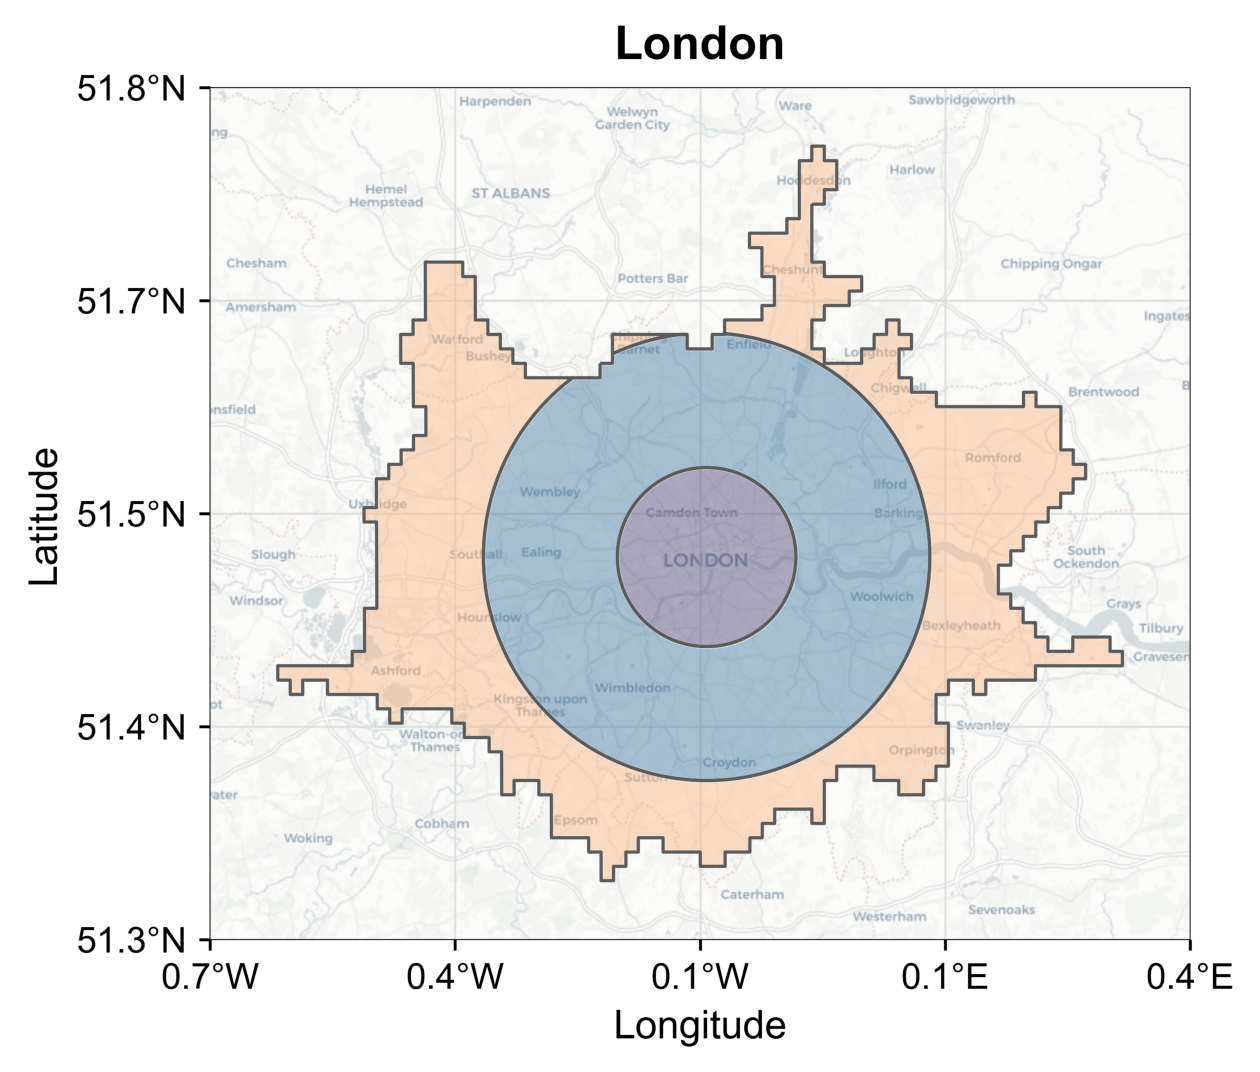

In [2]:
def ring_schematic(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 7: panel a."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import numpy as np
    import geopandas as gpd
    import matplotlib.pyplot as plt
    from pyproj import Transformer
    import contextily as ctx

    from shapely.ops import unary_union

    try:
        from shapely import make_valid as shp_make_valid
    except Exception:
        try:
            from shapely.validation import make_valid as shp_make_valid
        except Exception:
            shp_make_valid = None

    RING_FP = Path(str(project_root / 'GIS/GHSL_city_rings/london, United Kingdom/all_rings.geojson'))

    OUT_DIR = output_dir
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    FIG_W = 5.0
    FIG_H = 5.0
    DPI = 600
    DPI_JPG = 400

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 13
    LABEL_SIZE = 11
    TICK_SIZE = 10
    SPINE_LW = 0.25

    ZONE_ORDER = ["urban_outer", "urban_inner", "urban_centre"]
    ZONE_COLORS = {
        "urban_centre": "#3f3770",
        "urban_inner":  "#3573a1",
        "urban_outer":  "#feb37b",
    }

    FILL_ALPHA = 0.42
    EDGE_COLOR = "white"
    EDGE_LW = 1.2
    BOUNDARY_COLOR = "#5a5a5a"
    BOUNDARY_LW = 0.9

    BASEMAP_ALPHA = 0.92
    PADDING_RATIO = 0.08

    SHOW_TITLE = True
    TITLE_TEXT = "London"

    BASEMAP_PROVIDER = ctx.providers.CartoDB.Positron

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def format_lon(x):
        if x < 0:
            return f"{abs(x):.1f}°W"
        elif x > 0:
            return f"{x:.1f}°E"
        return "0°"

    def format_lat(y):
        if y < 0:
            return f"{abs(y):.1f}°S"
        elif y > 0:
            return f"{y:.1f}°N"
        return "0°"

    def add_padding(bounds, ratio=0.08):
        xmin, ymin, xmax, ymax = bounds
        dx = xmax - xmin
        dy = ymax - ymin
        return (
            xmin - dx * ratio,
            ymin - dy * ratio,
            xmax + dx * ratio,
            ymax + dy * ratio,
        )

    def make_lonlat_ticks(ax, transformer_to_lonlat, n_xticks=5, n_yticks=5):
        xmin, xmax = ax.get_xlim()
        ymin, ymax = ax.get_ylim()

        xticks = np.linspace(xmin, xmax, n_xticks)
        yticks = np.linspace(ymin, ymax, n_yticks)

        mid_y = (ymin + ymax) / 2
        xlabels = []
        for x in xticks:
            lon, _ = transformer_to_lonlat.transform(x, mid_y)
            xlabels.append(format_lon(lon))

        mid_x = (xmin + xmax) / 2
        ylabels = []
        for y in yticks:
            _, lat = transformer_to_lonlat.transform(mid_x, y)
            ylabels.append(format_lat(lat))

        ax.set_xticks(xticks)
        ax.set_xticklabels(xlabels)
        ax.set_yticks(yticks)
        ax.set_yticklabels(ylabels)

    def clean_geometry(geom):
        if geom is None or geom.is_empty:
            return None

        try:
            if not geom.is_valid:
                if shp_make_valid is not None:
                    geom = shp_make_valid(geom)
                else:
                    geom = geom.buffer(0)
        except Exception:
            try:
                geom = geom.buffer(0)
            except Exception:
                return None

        if geom is None or geom.is_empty:
            return None

        if geom.geom_type == "GeometryCollection":
            polys = [g for g in geom.geoms if g.geom_type in ("Polygon", "MultiPolygon") and not g.is_empty]
            if len(polys) == 0:
                return None
            try:
                geom = unary_union(polys)
            except Exception:
                geom = polys[0]

        if geom is None or geom.is_empty:
            return None

        return geom

    def dissolve_safe(gdf, by_col):
        """
        修复 geometry 后 dissolve。
        如果 dissolve 仍失败，则退回为不 dissolve 的 exploded 版本。
        """
        gdf = gdf.copy()
        gdf["geometry"] = gdf.geometry.apply(clean_geometry)
        gdf = gdf[gdf.geometry.notna()].copy()
        gdf = gdf[~gdf.geometry.is_empty].copy()

        if gdf.empty:
            raise ValueError("All geometries became empty after cleaning.")

        gdf = gdf.explode(index_parts=False).reset_index(drop=True)

        try:
            out = gdf.dissolve(by=by_col, as_index=False)
            out = out.explode(index_parts=False).reset_index(drop=True)
            return out
        except Exception as e:
            print(f"[Warning] dissolve failed after cleaning: {e}")
            print("[Warning] Fallback to exploded geometries without dissolve.")
            return gdf[[by_col, "geometry"]].copy()

    if not RING_FP.exists():
        raise FileNotFoundError(f"File not found: {RING_FP}")

    gdf = gpd.read_file(RING_FP)

    if gdf.empty:
        raise ValueError("GeoJSON is empty.")

    if gdf.crs is None:
        gdf = gdf.set_crs(epsg=4326)

    if "zone" not in gdf.columns:
        raise ValueError("Missing 'zone' column in all_rings.geojson")

    gdf = gdf[gdf["zone"].isin(ZONE_ORDER)].copy()
    gdf = gdf[gdf.geometry.notna()].copy()
    gdf = gdf[~gdf.geometry.is_empty].copy()

    if gdf.empty:
        raise ValueError("No valid zone rows found. Expected urban_centre / urban_inner / urban_outer.")

    gdf_3857 = gdf.to_crs(epsg=3857)

    gdf_plot = dissolve_safe(gdf_3857, by_col="zone")

    to_lonlat = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

    bounds = gdf_plot.total_bounds
    xmin, ymin, xmax, ymax = add_padding(bounds, ratio=PADDING_RATIO)

    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ctx.add_basemap(
        ax,
        source=BASEMAP_PROVIDER,
        alpha=BASEMAP_ALPHA,
        attribution=False
    )

    for zone in ZONE_ORDER:
        sub = gdf_plot[gdf_plot["zone"] == zone]
        if sub.empty:
            continue

        sub.plot(
            ax=ax,
            facecolor=ZONE_COLORS[zone],
            edgecolor=EDGE_COLOR,
            linewidth=EDGE_LW,
            alpha=FILL_ALPHA,
            zorder=3
        )

    gdf_plot.boundary.plot(
        ax=ax,
        color=BOUNDARY_COLOR,
        linewidth=BOUNDARY_LW,
        zorder=4
    )

    make_lonlat_ticks(ax, to_lonlat, n_xticks=5, n_yticks=5)

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    if SHOW_TITLE:
        ax.set_title(TITLE_TEXT, pad=8, weight="bold")

    ax.grid(True, color="#d9d9d9", linewidth=0.6, alpha=0.75, zorder=1)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(SPINE_LW)

    ax.tick_params(axis="both", length=3, width=0.8)

    plt.tight_layout()

    fig.savefig(OUT_DIR / "london_3ring_map_reference_style_no_legend_no_center.png", dpi=DPI, bbox_inches="tight")
    fig.savefig(OUT_DIR / "london_3ring_map_reference_style_no_legend_no_center.svg", bbox_inches="tight")
    fig.savefig(
        OUT_DIR / "london_3ring_map_reference_style_no_legend_no_center.jpg",
        dpi=DPI_JPG,
        bbox_inches="tight",
        format="jpg"
    )

    pass
    plt.close(fig)

output_dir = OUTPUT_ROOT / "a"
saved_map = PROJECT_ROOT / "GIS/GHSL_city_rings/london, United Kingdom/figure_outputs/london_3ring_map_reference_style_no_legend_no_center.png"
if USE_SAVED_MAPS and saved_map.exists():
    print("Ring map: showing the original saved export; online basemap not fetched in this run.")
    show_saved(saved_map)
else:
    with plt.rc_context():
        ring_schematic(DATA_DIR, PROJECT_ROOT, output_dir)
    plt.close("all")
    show_saved(output_dir / "london_3ring_map_reference_style_no_legend_no_center.png")


## b — Recurrence boxplot
Source: `Fig5.ipynb`, cell 2.

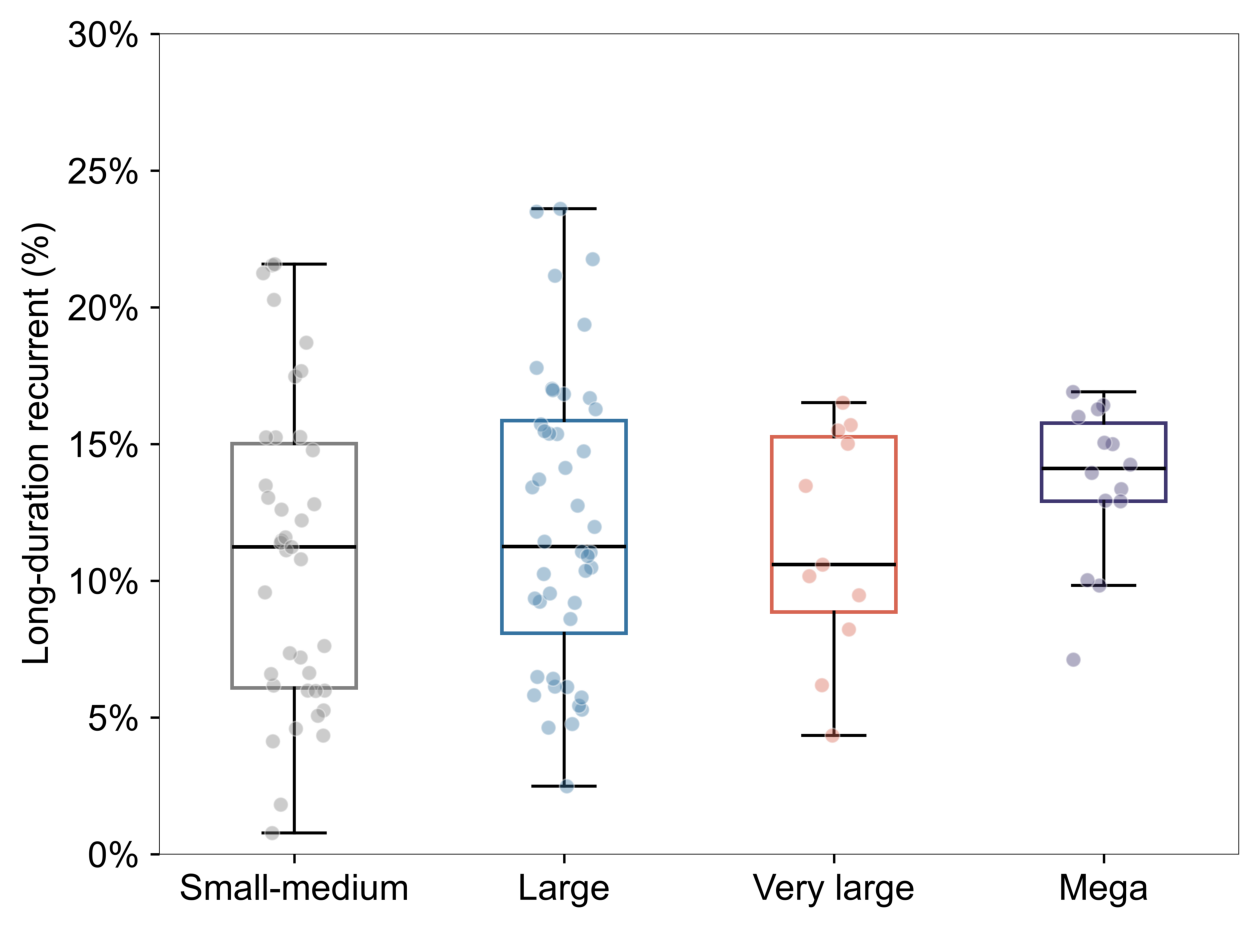

In [3]:
def recurrence_boxplot(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 2: panel b."""
    output_dir.mkdir(parents=True, exist_ok=True)
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick
    from pathlib import Path

    STAGE0_DIR = Path(str(project_root / 'GIS/segment_congestion_all_cities/fig5_stage0_outputs'))
    FIG_OUT_DIR = output_dir
    FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG = 400

    AX_W = 5.0
    AX_H = 3.8
    LEFT_MARGIN = 0.95
    RIGHT_MARGIN = 0.30
    BOTTOM_MARGIN = 0.85
    TOP_MARGIN = 0.25

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10

    SPINE_LW = 0.25

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)": "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)": "#3f3770",
    }

    DISPLAY_GROUP_LABELS = {
        "Small (<1M)": "Small-medium",
        "Medium (1-5M)": "Large",
        "Large (5-10M)": "Very large",
        "Mega (10M+)": "Mega",
    }

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def create_figure_with_exact_axes_size(
        ax_w=5.0,
        ax_h=4.0,
        left_margin=0.95,
        right_margin=0.30,
        bottom_margin=0.85,
        top_margin=0.25,
        dpi=140
    ):
        fig_w = left_margin + ax_w + right_margin
        fig_h = bottom_margin + ax_h + top_margin

        fig = plt.figure(figsize=(fig_w, fig_h), dpi=dpi)

        ax_left = left_margin / fig_w
        ax_bottom = bottom_margin / fig_h
        ax_width = ax_w / fig_w
        ax_height = ax_h / fig_h

        ax = fig.add_axes([ax_left, ax_bottom, ax_width, ax_height])
        return fig, ax

    Y_COL = "share_persistent_recurrent"
    Y_LABEL = "Long-duration recurrent (%)"
    OUT_STUB = "Fig5b_city_level_persistent_recurrent_share"

    Y_MIN = 0.0
    Y_MAX = 0.30
    POINT_SIZE = 24
    POINT_ALPHA = 0.4
    JITTER_WIDTH = 0.12
    BOX_WIDTH = 0.46

    city_df = pd.read_csv(STAGE0_DIR / "city_segment_type_shares.csv")

    plot_city = city_df.dropna(subset=[Y_COL, "city_size_group"]).copy()
    plot_city["group_order"] = plot_city["city_size_group"].map({g: i for i, g in enumerate(GROUP_ORDER)})
    plot_city = (
        plot_city.dropna(subset=["group_order"])
        .sort_values(["group_order", "population"], ascending=[True, True])
        .drop(columns="group_order")
        .reset_index(drop=True)
    )

    positions = np.arange(len(GROUP_ORDER))

    valid_groups = []
    valid_positions = []
    data_by_group_valid = []

    for i, g in enumerate(GROUP_ORDER):
        vals = plot_city.loc[plot_city["city_size_group"] == g, Y_COL].values.astype(float)
        vals = vals[np.isfinite(vals)]
        if len(vals) > 0:
            valid_groups.append(g)
            valid_positions.append(i)
            data_by_group_valid.append(vals)

    fig, ax = create_figure_with_exact_axes_size(
        ax_w=AX_W,
        ax_h=AX_H,
        left_margin=LEFT_MARGIN,
        right_margin=RIGHT_MARGIN,
        bottom_margin=BOTTOM_MARGIN,
        top_margin=TOP_MARGIN,
        dpi=DPI_SHOW
    )

    if len(data_by_group_valid) > 0:
        bp = ax.boxplot(
            data_by_group_valid,
            positions=valid_positions,
            widths=BOX_WIDTH,
            patch_artist=True,
            showfliers=False,
            medianprops=dict(color="black", linewidth=1.2),
            boxprops=dict(facecolor="white", edgecolor="black", linewidth=1.0),
            whiskerprops=dict(color="black", linewidth=1.0),
            capprops=dict(color="black", linewidth=1.0),
        )

        for patch, g in zip(bp["boxes"], valid_groups):
            patch.set_edgecolor(GROUP_COLORS[g])
            patch.set_linewidth(1.2)
            patch.set_facecolor("white")

        for whisker in bp["whiskers"]:
            whisker.set_color("black")
        for cap in bp["caps"]:
            cap.set_color("black")

    np.random.seed(42)

    for i, g in enumerate(GROUP_ORDER):
        sub = plot_city.loc[plot_city["city_size_group"] == g, Y_COL].values.astype(float)
        sub = sub[np.isfinite(sub)]
        if len(sub) == 0:
            continue

        jitter = np.random.uniform(-JITTER_WIDTH, JITTER_WIDTH, size=len(sub))
        ax.scatter(
            np.full(len(sub), i) + jitter,
            sub,
            s=POINT_SIZE,
            facecolor=GROUP_COLORS[g],
            edgecolor="white",
            linewidth=0.5,
            alpha=POINT_ALPHA,
            zorder=3
        )

    xticklabels = [DISPLAY_GROUP_LABELS[g] for g in GROUP_ORDER]

    ax.set_xticks(positions)
    ax.set_xticklabels(xticklabels)

    ax.set_ylabel(Y_LABEL)
    ax.set_ylim(Y_MIN, Y_MAX)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(SPINE_LW)

    ax.grid(False)
    ax.tick_params(axis="both", length=3, width=0.8)

    fig.savefig(
        FIG_OUT_DIR / f"{OUT_STUB}.png",
        dpi=DPI_SAVE,
        bbox_inches="tight"
    )
    fig.savefig(
        FIG_OUT_DIR / f"{OUT_STUB}.svg",
        bbox_inches="tight"
    )
    fig.savefig(
        CODE_OUT_DIR / f"{OUT_STUB}.jpg",
        dpi=DPI_JPG,
        bbox_inches="tight",
        format="jpg"
    )

    pass
    plt.close(fig)

output_dir = OUTPUT_ROOT / "b"
with plt.rc_context():
    recurrence_boxplot(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'Fig5b_city_level_persistent_recurrent_share.png')


## c — Ring lines
Source: `Fig5.ipynb`, cell 5.

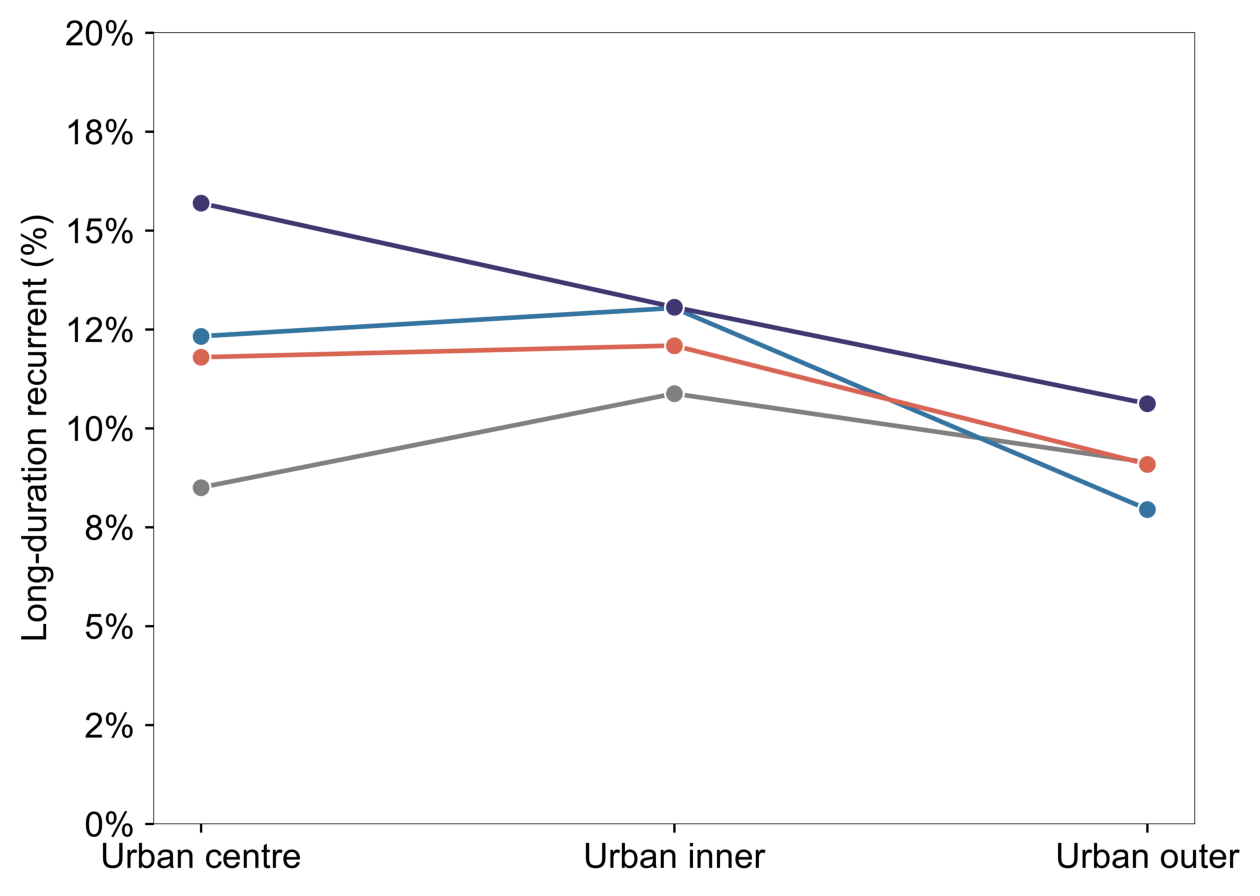

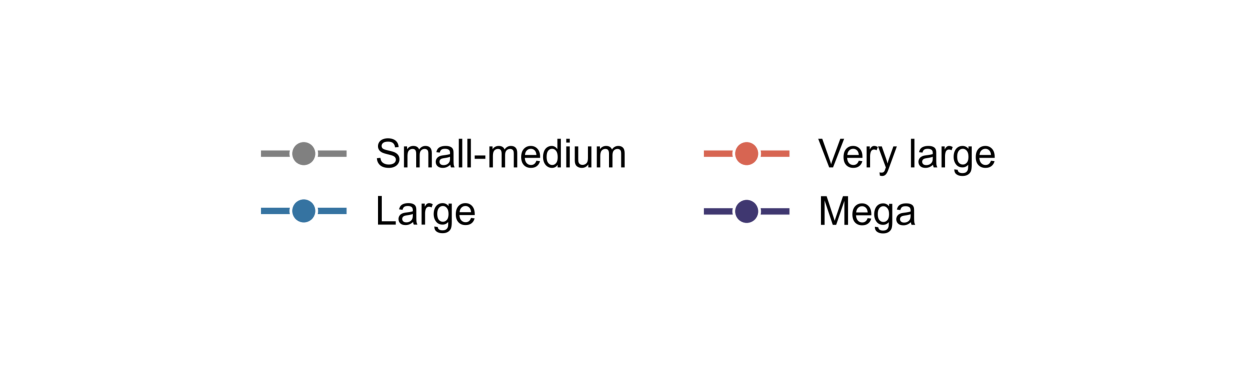

In [4]:
def ring_lines(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 5: panel c."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    STAGE0_DIR = Path(str(project_root / 'GIS/segment_congestion_all_cities/fig5_stage0_outputs'))

    FIG_OUT_DIR = output_dir
    FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    GROUP_SUMMARY_FP = STAGE0_DIR / "ring_group_summary.csv"

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]
    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }

    DISPLAY_GROUP_LABELS = {
        "Small (<1M)":   "Small-medium",
        "Medium (1-5M)": "Large",
        "Large (5-10M)": "Very large",
        "Mega (10M+)":   "Mega",
    }

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG  = 400

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10
    SPINE_LW = 0.25

    LINE_WIDTH = 1.6
    MARKER_SIZE = 6.5

    AX_W = 5.0
    AX_H = 3.8

    LEFT_MARGIN = 0.95
    RIGHT_MARGIN = 0.25
    BOTTOM_MARGIN = 0.80
    TOP_MARGIN = 0.20

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def create_figure_with_exact_axes_size(
        ax_w=5.2,
        ax_h=3.5,
        left_margin=0.95,
        right_margin=0.25,
        bottom_margin=0.80,
        top_margin=0.20,
        dpi=140
    ):
        fig_w = left_margin + ax_w + right_margin
        fig_h = bottom_margin + ax_h + top_margin

        fig = plt.figure(figsize=(fig_w, fig_h), dpi=dpi)

        ax_left = left_margin / fig_w
        ax_bottom = bottom_margin / fig_h
        ax_width = ax_w / fig_w
        ax_height = ax_h / fig_h

        ax = fig.add_axes([ax_left, ax_bottom, ax_width, ax_height])
        return fig, ax

    def save_standalone_legend(handles, labels, out_png, out_svg, out_jpg,
                               ncol=2, figsize=(4.0, 1.1), dpi_png=600, dpi_jpg=400):
        fig_leg = plt.figure(figsize=figsize)
        ax_leg = fig_leg.add_axes([0, 0, 1, 1])
        ax_leg.axis("off")

        ax_leg.legend(
            handles, labels,
            loc="center",
            frameon=False,
            ncol=ncol
        )

        fig_leg.savefig(out_png, dpi=dpi_png, bbox_inches="tight")
        fig_leg.savefig(out_svg, bbox_inches="tight")
        fig_leg.savefig(out_jpg, dpi=dpi_jpg, bbox_inches="tight", format="jpg")
        plt.close(fig_leg)

    if not GROUP_SUMMARY_FP.exists():
        raise FileNotFoundError(f"Missing {GROUP_SUMMARY_FP}. Run stage0 first.")

    group_df = pd.read_csv(GROUP_SUMMARY_FP)

    if group_df.empty:
        raise ValueError("ring_group_summary.csv is empty.")

    print("Loaded ring-group summary:")
    print(group_df.head().to_string(index=False))

    full_index = pd.MultiIndex.from_product(
        [GROUP_ORDER, RING_ORDER],
        names=["city_size_group", "ring"]
    )

    plot_df = (
        group_df.set_index(["city_size_group", "ring"])
        .reindex(full_index)
        .reset_index()
    )

    plot_df["ring_label"] = plot_df["ring"].map(RING_LABELS)

    fig, ax = create_figure_with_exact_axes_size(
        ax_w=AX_W,
        ax_h=AX_H,
        left_margin=LEFT_MARGIN,
        right_margin=RIGHT_MARGIN,
        bottom_margin=BOTTOM_MARGIN,
        top_margin=TOP_MARGIN,
        dpi=DPI_SHOW
    )

    x = np.arange(len(RING_ORDER))
    plotted_groups = []

    for g in GROUP_ORDER:
        sub = plot_df[plot_df["city_size_group"] == g].copy()
        sub["ring_order"] = sub["ring"].map({r: i for i, r in enumerate(RING_ORDER)})
        sub = sub.sort_values("ring_order")

        y = sub["median"].values.astype(float)

        if len(y) != len(RING_ORDER) or np.all(np.isnan(y)):
            print(f"Skip plotting group with no valid data: {g}")
            continue

        ax.plot(
            x, y,
            color=GROUP_COLORS[g],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=MARKER_SIZE,
            markerfacecolor=GROUP_COLORS[g],
            markeredgecolor="white",
            markeredgewidth=0.7,
            label=DISPLAY_GROUP_LABELS[g]
        )
        plotted_groups.append(g)

    ax.set_xticks(x)
    ax.set_xticklabels([RING_LABELS[r] for r in RING_ORDER])
    ax.set_ylabel("Long-duration recurrent (%)")

    valid_y = plot_df["median"].dropna().values
    if len(valid_y) == 0:
        raise ValueError("No valid median values found in ring_group_summary.csv")

    y_max = np.nanmax(valid_y)
    y_max = max(0.20, y_max * 1.20)
    y_max = np.ceil(y_max / 0.05) * 0.05

    ax.set_ylim(0, y_max)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(SPINE_LW)

    ax.grid(False)
    ax.tick_params(axis="both", length=3, width=0.8)

    handles, labels = ax.get_legend_handles_labels()

    main_stub = "Fig5c_persistent_share_among_congested_by_ring_summary_only_no_legend"

    fig.savefig(
        FIG_OUT_DIR / f"{main_stub}.png",
        dpi=DPI_SAVE,
        bbox_inches="tight"
    )
    fig.savefig(
        FIG_OUT_DIR / f"{main_stub}.svg",
        bbox_inches="tight"
    )
    fig.savefig(
        CODE_OUT_DIR / f"{main_stub}.jpg",
        dpi=DPI_JPG,
        bbox_inches="tight",
        format="jpg"
    )

    pass
    plt.close(fig)

    legend_stub = "Fig5c_persistent_share_among_congested_by_ring_legend"

    save_standalone_legend(
        handles=handles,
        labels=labels,
        out_png=FIG_OUT_DIR / f"{legend_stub}.png",
        out_svg=FIG_OUT_DIR / f"{legend_stub}.svg",
        out_jpg=CODE_OUT_DIR / f"{legend_stub}.jpg",
        ncol=2,
        figsize=(4.2, 1.1),
        dpi_png=DPI_SAVE,
        dpi_jpg=DPI_JPG
    )

    print("\nDone.")
    print("Main figure saved without legend:")
    print(FIG_OUT_DIR / f"{main_stub}.png")
    print(FIG_OUT_DIR / f"{main_stub}.svg")
    print(CODE_OUT_DIR / f"{main_stub}.jpg")

    print("\nStandalone legend saved:")
    print(FIG_OUT_DIR / f"{legend_stub}.png")
    print(FIG_OUT_DIR / f"{legend_stub}.svg")
    print(CODE_OUT_DIR / f"{legend_stub}.jpg")

output_dir = OUTPUT_ROOT / "c"
with plt.rc_context():
    ring_lines(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'Fig5c_persistent_share_among_congested_by_ring_summary_only_no_legend.png')
show_saved(output_dir / 'Fig5c_persistent_share_among_congested_by_ring_legend.png')


## d — Paris
Source: `Fig5.ipynb`, cells 3 and 6. The map and corresponding stacked bars are kept together.

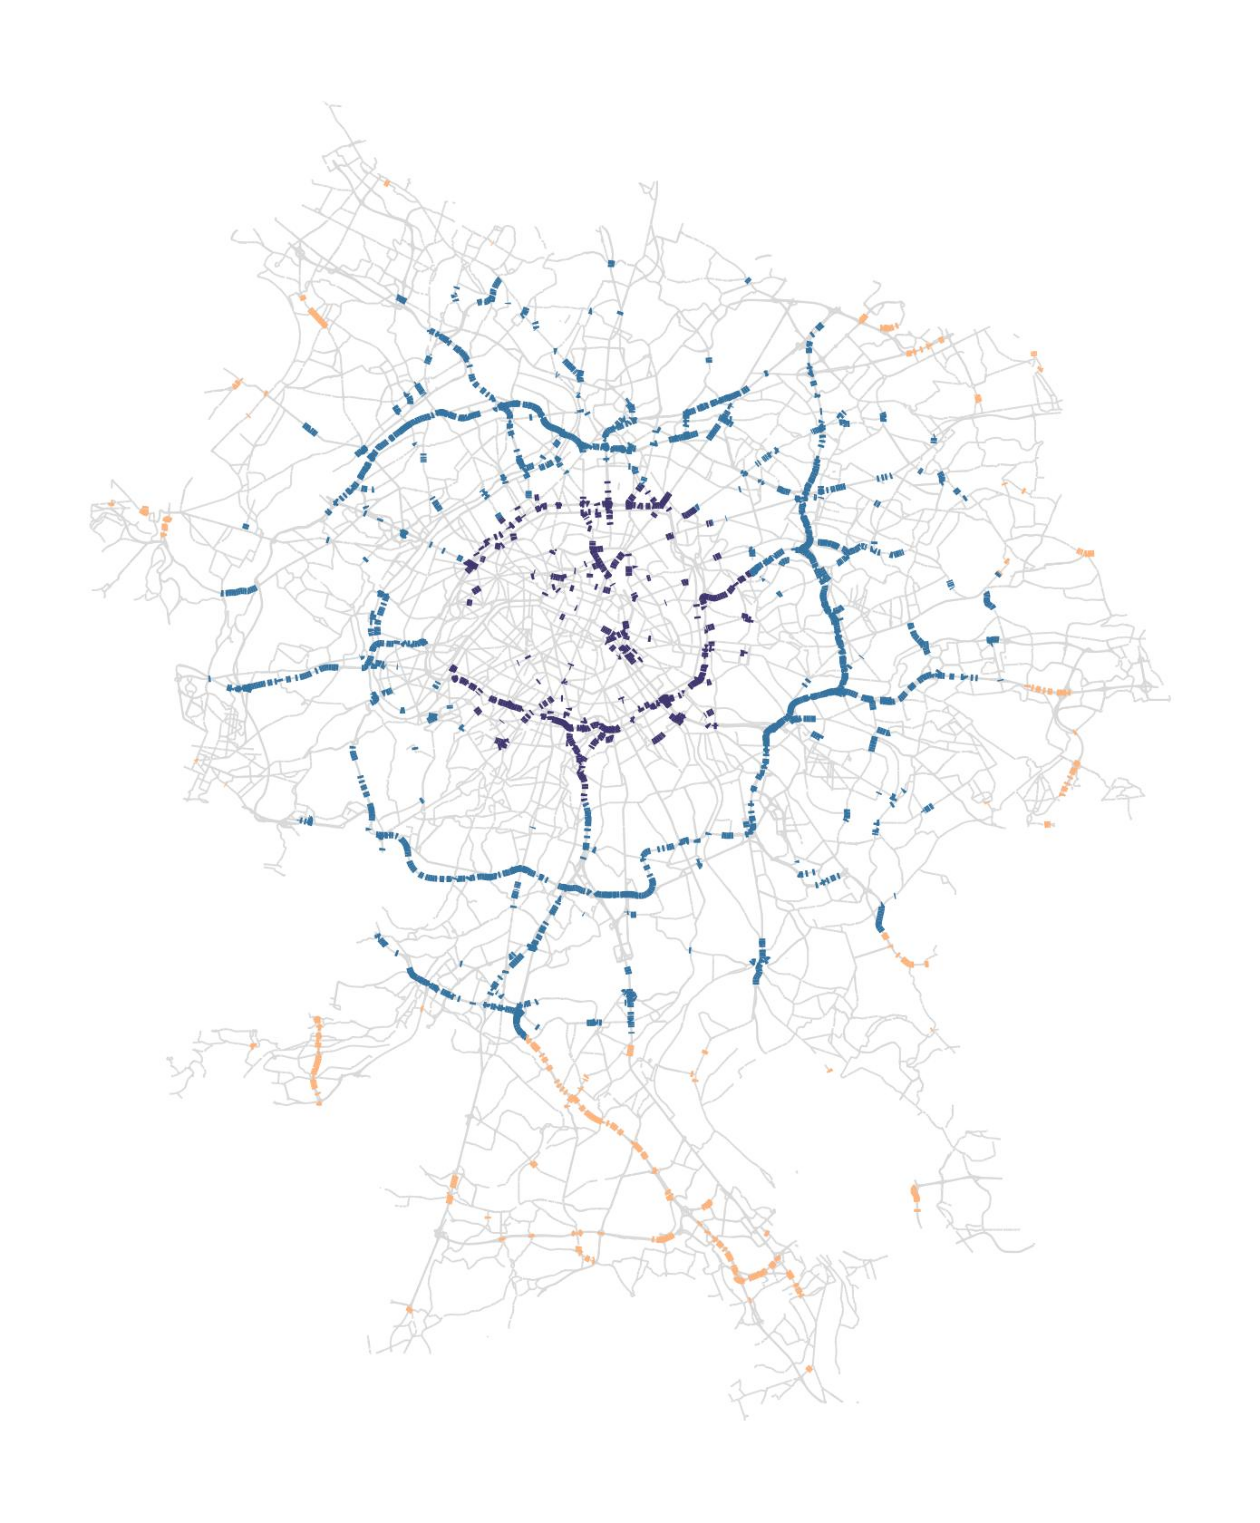

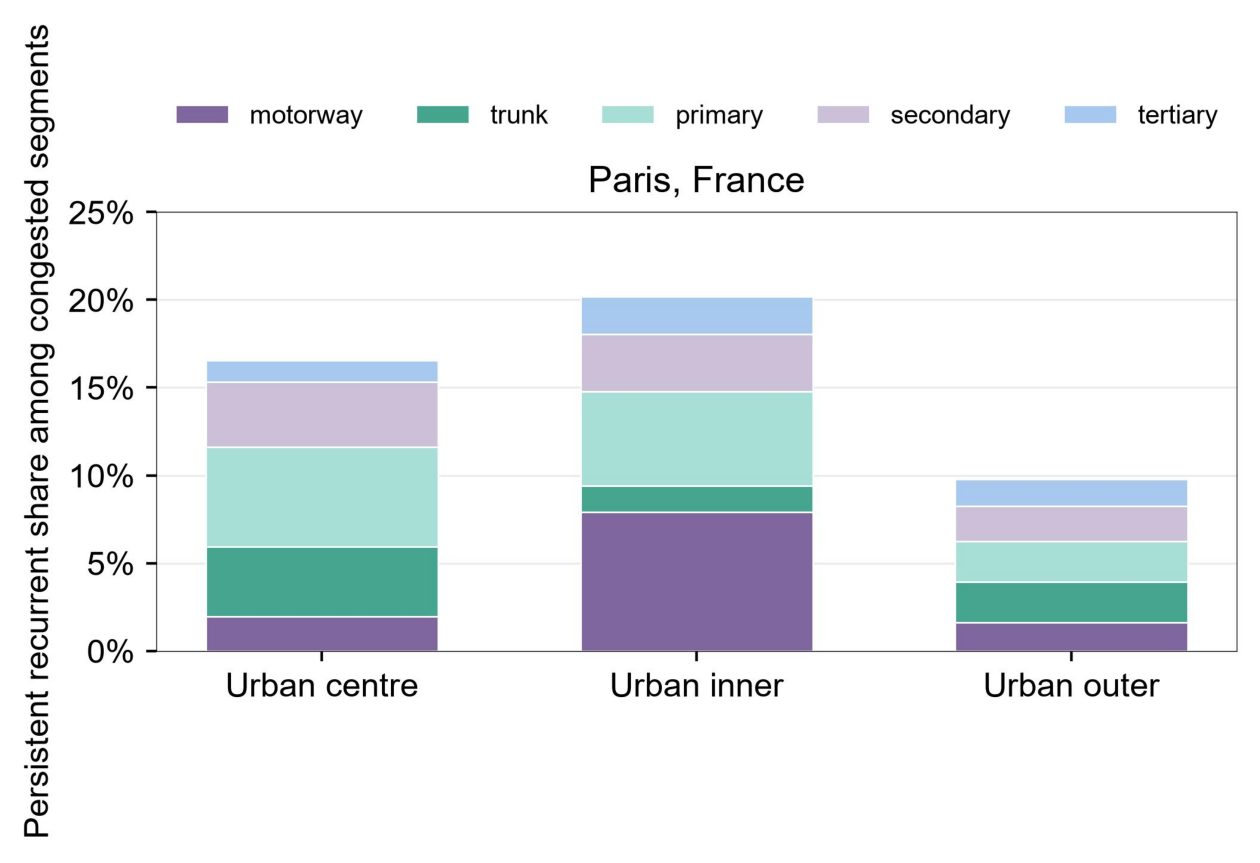

In [5]:
def city_maps(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 3: maps in panels d-i."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    STAGE0_DIR = Path(str(project_root / 'GIS/segment_congestion_all_cities/fig5_stage0_outputs'))

    FIG_OUT_DIR = output_dir
    FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CITY_MAP_DIR = FIG_OUT_DIR / "fig5c_city_maps"
    CITY_MAP_DIR.mkdir(parents=True, exist_ok=True)

    GROUP_SUMMARY_FP = STAGE0_DIR / "ring_group_summary.csv"
    MANIFEST_FP = STAGE0_DIR / "all_city_geojson_manifest.csv"

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]
    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }
    RING_COLORS = {
        "urban_centre": "#3f3770",
        "urban_inner": "#3573a1",
        "urban_outer": "#feb37b",
    }

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG  = 400

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10
    SPINE_LW = 0.25

    LINE_WIDTH = 1.6
    MARKER_SIZE = 6.5

    MAP_BASE_LINEWIDTH = 0.35
    MAP_PR_LINEWIDTH = 1.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    manifest_df = pd.read_csv(MANIFEST_FP)
    selected_cities = {'paris, france'}
    manifest_df = manifest_df[manifest_df["city"].str.lower().isin(selected_cities)]
    if len(manifest_df) != 1:
        raise ValueError("Expected one matching city in the map manifest.")
    saved_count = 0
    skipped_count = 0

    for _, row in manifest_df.iterrows():
        city_label = row["city"]

        geo_val = row.get("processed_full_geojson", "")
        geo_fp_str = "" if pd.isna(geo_val) else str(geo_val).strip()

        if geo_fp_str == "":
            print(f"Skip {city_label}: no processed_full_geojson path")
            skipped_count += 1
            continue

        geo_fp = STAGE0_DIR / "processed_geojson_all_cities" / Path(geo_fp_str.replace("\\", "/")).name

        if not geo_fp.exists():
            print(f"Missing processed geojson: {geo_fp}")
            skipped_count += 1
            continue

        try:
            gdf = gpd.read_file(geo_fp)
        except Exception as e:
            print(f"Failed reading {geo_fp}: {e}")
            skipped_count += 1
            continue

        required_cols = {"segment_type", "ring_final"}
        missing_cols = required_cols - set(gdf.columns)
        if missing_cols:
            print(f"Skip {city_label}: missing columns {missing_cols}")
            skipped_count += 1
            continue

        safe_name = (
            str(city_label).lower()
            .replace(",", "")
            .replace(" ", "_")
            .replace("/", "_")
        )

        fig, ax = plt.subplots(figsize=(6.1, 5.2), dpi=DPI_SHOW)

        gdf.plot(ax=ax, color="#d9d9d9", linewidth=MAP_BASE_LINEWIDTH)

        pr = gdf[gdf["segment_type"] == "Persistent recurrent"].copy()

        for ring in RING_ORDER:
            sub = pr[pr["ring_final"] == ring]
            if len(sub) == 0:
                continue
            sub.plot(
                ax=ax,
                color=RING_COLORS[ring],
                linewidth=MAP_PR_LINEWIDTH
            )

        ax.set_axis_off()

        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.svg",
            bbox_inches="tight"
        )
        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )

        plt.close(fig)
        saved_count += 1

    print("\nFig.5c done.")
    print(f"Saved Fig.5c line plot to: {FIG_OUT_DIR}")
    print(f"Saved all city maps to: {CITY_MAP_DIR}")
    print(f"Saved city maps: {saved_count}")
    print(f"Skipped city maps: {skipped_count}")

def city_bars(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 6: bars in panels d-i; reads the saved matching results."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import re

    import unicodedata

    import numpy as np

    import pandas as pd

    import geopandas as gpd

    import matplotlib.pyplot as plt

    import matplotlib.ticker as mtick

    FIG_W = 5.5

    FIG_H = 3

    DPI = 600

    DPI_JPG = 400

    FONT_FAMILY = "Arial"

    TITLE_SIZE = 11

    LABEL_SIZE = 10

    TICK_SIZE = 10

    LEGEND_SIZE = 8

    SPINE_LW = 0.25

    BAR_WIDTH = 0.62

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]

    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }

    ROAD_ORDER = ["motorway", "trunk", "primary", "secondary", "tertiary"]

    ROAD_COLORS = {
        "motorway":  "#80669f",
        "trunk":     "#46a58f",
        "primary":   "#a7dfd6",
        "secondary": "#ccc0d9",
        "tertiary":  "#a7c9ef",
    }

    TARGET_HIGHWAYS = set(ROAD_ORDER)

    MAX_MATCH_DIST_M = 35.0

    DENOMINATOR_TARGET_FIVE_ONLY = True

    USE_LENGTH_IF_AVAILABLE = True

    YMAX_FIXED = 0.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def normalize_text(text):
        if text is None:
            return ""
        text = str(text).strip().lower()
        text = unicodedata.normalize("NFKD", text)
        text = "".join(ch for ch in text if not unicodedata.combining(ch))
        text = text.replace("&", "and")
        text = text.replace("_", " ")
        text = text.replace("-", " ")
        text = re.sub(r"[^\w\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def safe_name(text):
        s = normalize_text(text)
        s = s.replace(" ", "_")
        s = re.sub(r"_+", "_", s)
        return s

    def plot_city_stacked_bar(city_label, plot_df, total_df):
        x = np.arange(len(RING_ORDER))
        fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

        bottoms = np.zeros(len(RING_ORDER), dtype=float)

        for road in ROAD_ORDER:
            sub = (
                plot_df[plot_df["road_class"] == road]
                .set_index("ring_final")
                .reindex(RING_ORDER)
                .reset_index()
            )

            y = sub["share_of_all_congested"].values.astype(float)
            y = np.nan_to_num(y, nan=0.0)

            ax.bar(
                x,
                y,
                width=BAR_WIDTH,
                bottom=bottoms,
                color=ROAD_COLORS[road],
                edgecolor="white",
                linewidth=0.5,
                label=road
            )
            bottoms += y

        ax.set_ylim(0, YMAX_FIXED)
        ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

        ax.set_xticks(x)
        ax.set_xticklabels([RING_LABELS[r] for r in RING_ORDER])

        ax.set_ylabel("Persistent recurrent share among congested segments")
        ax.set_title(city_label)

        ax.grid(axis="y", alpha=0.25, linewidth=0.6)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_LW)

        ax.tick_params(axis="both", length=3, width=0.8)

        ax.legend(
            frameon=False,
            ncol=5,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.30)
        )

        fig.tight_layout()

        safe_city = safe_name(city_label)
        fig.savefig(FIG_DIR / f"{safe_city}_ring_highway_stacked.svg", bbox_inches="tight")
        fig.savefig(
            FIG_DIR / f"{safe_city}_ring_highway_stacked.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )
        plt.close(fig)
    FIG_DIR = output_dir
    stack_file = project_root / "GIS/segment_congestion_all_cities/fig5_highway_ring_outputs/csv/all_cities_ring_highway_stack_values.csv"
    stack = pd.read_csv(stack_file)
    stack = stack.loc[stack["city"] == 'Paris, France'].copy()
    if stack.empty:
        raise ValueError("City is missing from the saved bar table.")
    for city, city_data in stack.groupby("city", sort=False):
        total = city_data.groupby("ring_final", as_index=False)["share_of_all_congested"].sum().rename(columns={"share_of_all_congested": "total_pr_share"})
        plot_city_stacked_bar(city, city_data, total)

output_dir = OUTPUT_ROOT / "d"
with plt.rc_context():
    city_maps(DATA_DIR, PROJECT_ROOT, output_dir / "map")
with plt.rc_context():
    city_bars(DATA_DIR, PROJECT_ROOT, output_dir / "bars")
plt.close("all")
show_saved(output_dir / 'map/fig5c_city_maps/paris_france.jpg')
show_saved(output_dir / 'bars/paris_france_ring_highway_stacked.jpg')


## e — London
Source: `Fig5.ipynb`, cells 3 and 6. The map and corresponding stacked bars are kept together.

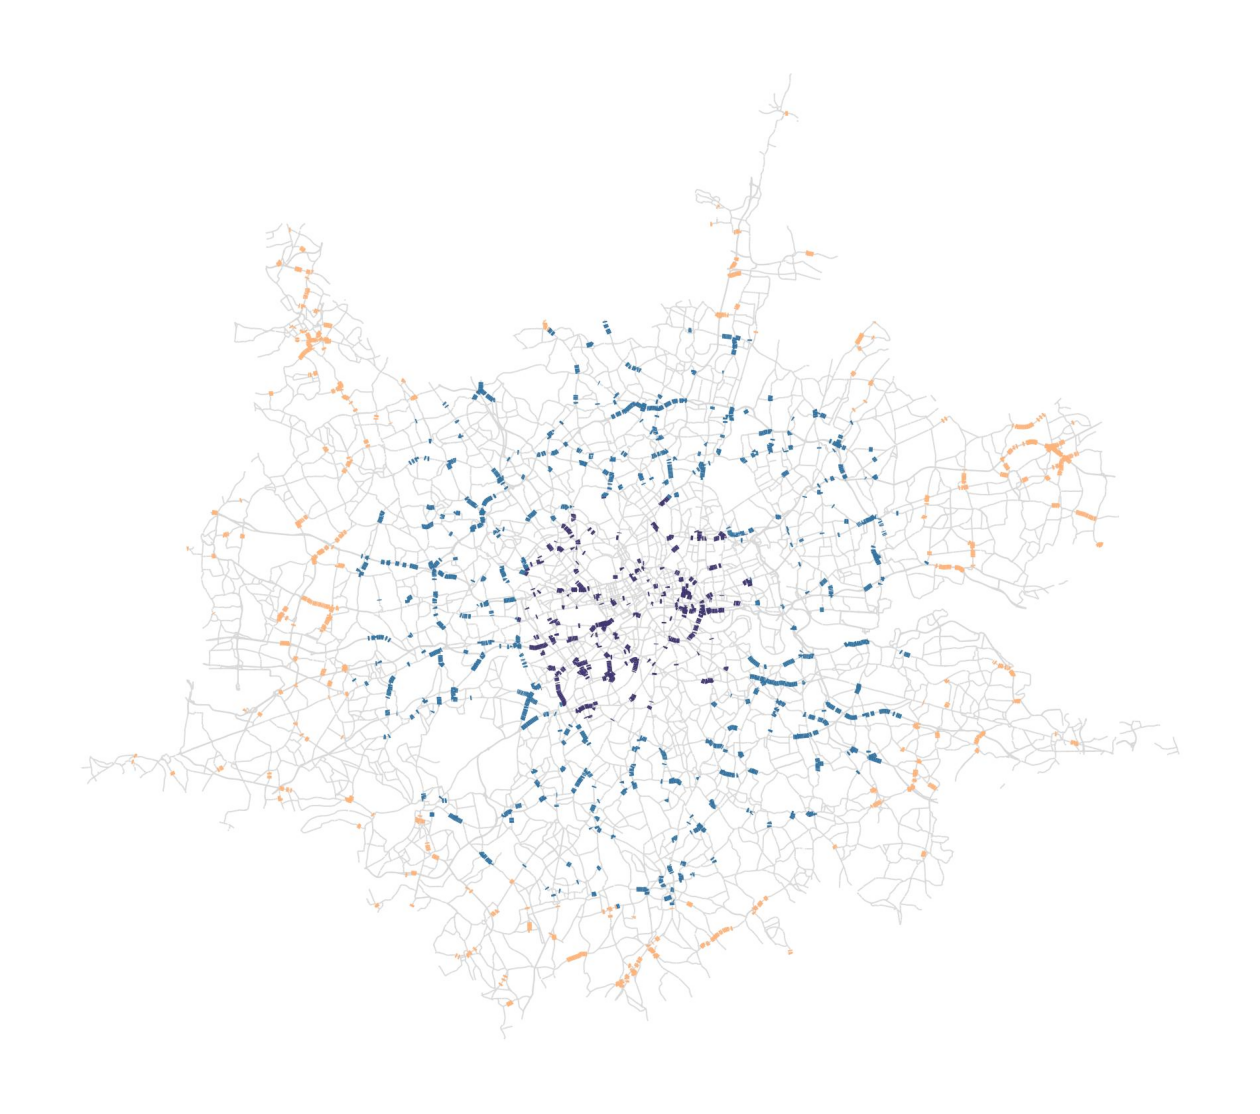

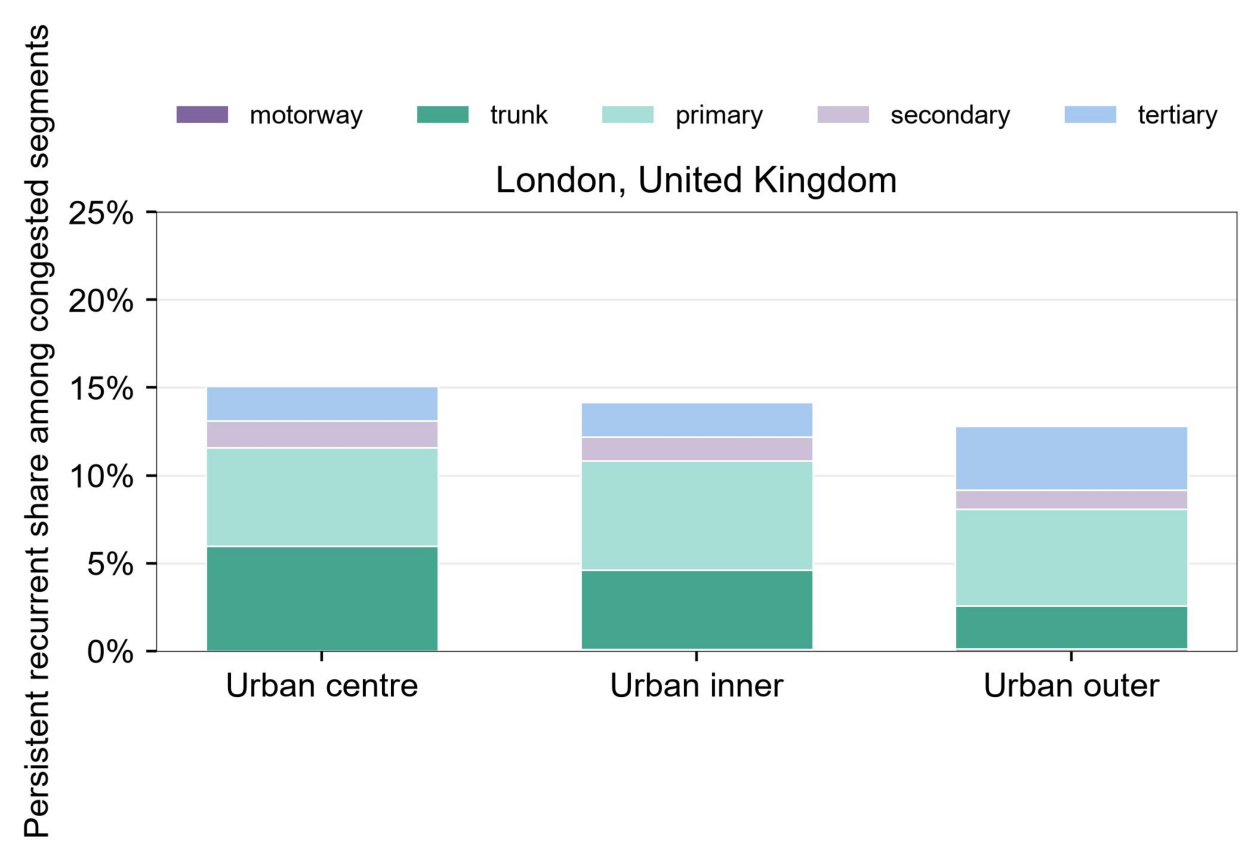

In [6]:
def city_maps(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 3: maps in panels d-i."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    STAGE0_DIR = Path(str(project_root / 'GIS/segment_congestion_all_cities/fig5_stage0_outputs'))

    FIG_OUT_DIR = output_dir
    FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CITY_MAP_DIR = FIG_OUT_DIR / "fig5c_city_maps"
    CITY_MAP_DIR.mkdir(parents=True, exist_ok=True)

    GROUP_SUMMARY_FP = STAGE0_DIR / "ring_group_summary.csv"
    MANIFEST_FP = STAGE0_DIR / "all_city_geojson_manifest.csv"

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]
    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }
    RING_COLORS = {
        "urban_centre": "#3f3770",
        "urban_inner": "#3573a1",
        "urban_outer": "#feb37b",
    }

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG  = 400

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10
    SPINE_LW = 0.25

    LINE_WIDTH = 1.6
    MARKER_SIZE = 6.5

    MAP_BASE_LINEWIDTH = 0.35
    MAP_PR_LINEWIDTH = 1.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    manifest_df = pd.read_csv(MANIFEST_FP)
    selected_cities = {'london, united kingdom'}
    manifest_df = manifest_df[manifest_df["city"].str.lower().isin(selected_cities)]
    if len(manifest_df) != 1:
        raise ValueError("Expected one matching city in the map manifest.")
    saved_count = 0
    skipped_count = 0

    for _, row in manifest_df.iterrows():
        city_label = row["city"]

        geo_val = row.get("processed_full_geojson", "")
        geo_fp_str = "" if pd.isna(geo_val) else str(geo_val).strip()

        if geo_fp_str == "":
            print(f"Skip {city_label}: no processed_full_geojson path")
            skipped_count += 1
            continue

        geo_fp = STAGE0_DIR / "processed_geojson_all_cities" / Path(geo_fp_str.replace("\\", "/")).name

        if not geo_fp.exists():
            print(f"Missing processed geojson: {geo_fp}")
            skipped_count += 1
            continue

        try:
            gdf = gpd.read_file(geo_fp)
        except Exception as e:
            print(f"Failed reading {geo_fp}: {e}")
            skipped_count += 1
            continue

        required_cols = {"segment_type", "ring_final"}
        missing_cols = required_cols - set(gdf.columns)
        if missing_cols:
            print(f"Skip {city_label}: missing columns {missing_cols}")
            skipped_count += 1
            continue

        safe_name = (
            str(city_label).lower()
            .replace(",", "")
            .replace(" ", "_")
            .replace("/", "_")
        )

        fig, ax = plt.subplots(figsize=(6.1, 5.2), dpi=DPI_SHOW)

        gdf.plot(ax=ax, color="#d9d9d9", linewidth=MAP_BASE_LINEWIDTH)

        pr = gdf[gdf["segment_type"] == "Persistent recurrent"].copy()

        for ring in RING_ORDER:
            sub = pr[pr["ring_final"] == ring]
            if len(sub) == 0:
                continue
            sub.plot(
                ax=ax,
                color=RING_COLORS[ring],
                linewidth=MAP_PR_LINEWIDTH
            )

        ax.set_axis_off()

        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.svg",
            bbox_inches="tight"
        )
        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )

        plt.close(fig)
        saved_count += 1

    print("\nFig.5c done.")
    print(f"Saved Fig.5c line plot to: {FIG_OUT_DIR}")
    print(f"Saved all city maps to: {CITY_MAP_DIR}")
    print(f"Saved city maps: {saved_count}")
    print(f"Skipped city maps: {skipped_count}")

def city_bars(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 6: bars in panels d-i; reads the saved matching results."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import re

    import unicodedata

    import numpy as np

    import pandas as pd

    import geopandas as gpd

    import matplotlib.pyplot as plt

    import matplotlib.ticker as mtick

    FIG_W = 5.5

    FIG_H = 3

    DPI = 600

    DPI_JPG = 400

    FONT_FAMILY = "Arial"

    TITLE_SIZE = 11

    LABEL_SIZE = 10

    TICK_SIZE = 10

    LEGEND_SIZE = 8

    SPINE_LW = 0.25

    BAR_WIDTH = 0.62

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]

    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }

    ROAD_ORDER = ["motorway", "trunk", "primary", "secondary", "tertiary"]

    ROAD_COLORS = {
        "motorway":  "#80669f",
        "trunk":     "#46a58f",
        "primary":   "#a7dfd6",
        "secondary": "#ccc0d9",
        "tertiary":  "#a7c9ef",
    }

    TARGET_HIGHWAYS = set(ROAD_ORDER)

    MAX_MATCH_DIST_M = 35.0

    DENOMINATOR_TARGET_FIVE_ONLY = True

    USE_LENGTH_IF_AVAILABLE = True

    YMAX_FIXED = 0.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def normalize_text(text):
        if text is None:
            return ""
        text = str(text).strip().lower()
        text = unicodedata.normalize("NFKD", text)
        text = "".join(ch for ch in text if not unicodedata.combining(ch))
        text = text.replace("&", "and")
        text = text.replace("_", " ")
        text = text.replace("-", " ")
        text = re.sub(r"[^\w\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def safe_name(text):
        s = normalize_text(text)
        s = s.replace(" ", "_")
        s = re.sub(r"_+", "_", s)
        return s

    def plot_city_stacked_bar(city_label, plot_df, total_df):
        x = np.arange(len(RING_ORDER))
        fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

        bottoms = np.zeros(len(RING_ORDER), dtype=float)

        for road in ROAD_ORDER:
            sub = (
                plot_df[plot_df["road_class"] == road]
                .set_index("ring_final")
                .reindex(RING_ORDER)
                .reset_index()
            )

            y = sub["share_of_all_congested"].values.astype(float)
            y = np.nan_to_num(y, nan=0.0)

            ax.bar(
                x,
                y,
                width=BAR_WIDTH,
                bottom=bottoms,
                color=ROAD_COLORS[road],
                edgecolor="white",
                linewidth=0.5,
                label=road
            )
            bottoms += y

        ax.set_ylim(0, YMAX_FIXED)
        ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

        ax.set_xticks(x)
        ax.set_xticklabels([RING_LABELS[r] for r in RING_ORDER])

        ax.set_ylabel("Persistent recurrent share among congested segments")
        ax.set_title(city_label)

        ax.grid(axis="y", alpha=0.25, linewidth=0.6)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_LW)

        ax.tick_params(axis="both", length=3, width=0.8)

        ax.legend(
            frameon=False,
            ncol=5,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.30)
        )

        fig.tight_layout()

        safe_city = safe_name(city_label)
        fig.savefig(FIG_DIR / f"{safe_city}_ring_highway_stacked.svg", bbox_inches="tight")
        fig.savefig(
            FIG_DIR / f"{safe_city}_ring_highway_stacked.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )
        plt.close(fig)
    FIG_DIR = output_dir
    stack_file = project_root / "GIS/segment_congestion_all_cities/fig5_highway_ring_outputs/csv/all_cities_ring_highway_stack_values.csv"
    stack = pd.read_csv(stack_file)
    stack = stack.loc[stack["city"] == 'London, United Kingdom'].copy()
    if stack.empty:
        raise ValueError("City is missing from the saved bar table.")
    for city, city_data in stack.groupby("city", sort=False):
        total = city_data.groupby("ring_final", as_index=False)["share_of_all_congested"].sum().rename(columns={"share_of_all_congested": "total_pr_share"})
        plot_city_stacked_bar(city, city_data, total)

output_dir = OUTPUT_ROOT / "e"
with plt.rc_context():
    city_maps(DATA_DIR, PROJECT_ROOT, output_dir / "map")
with plt.rc_context():
    city_bars(DATA_DIR, PROJECT_ROOT, output_dir / "bars")
plt.close("all")
show_saved(output_dir / 'map/fig5c_city_maps/london_united_kingdom.jpg')
show_saved(output_dir / 'bars/london_united_kingdom_ring_highway_stacked.jpg')


## f — Mexico City
Source: `Fig5.ipynb`, cells 3 and 6. The map and corresponding stacked bars are kept together.

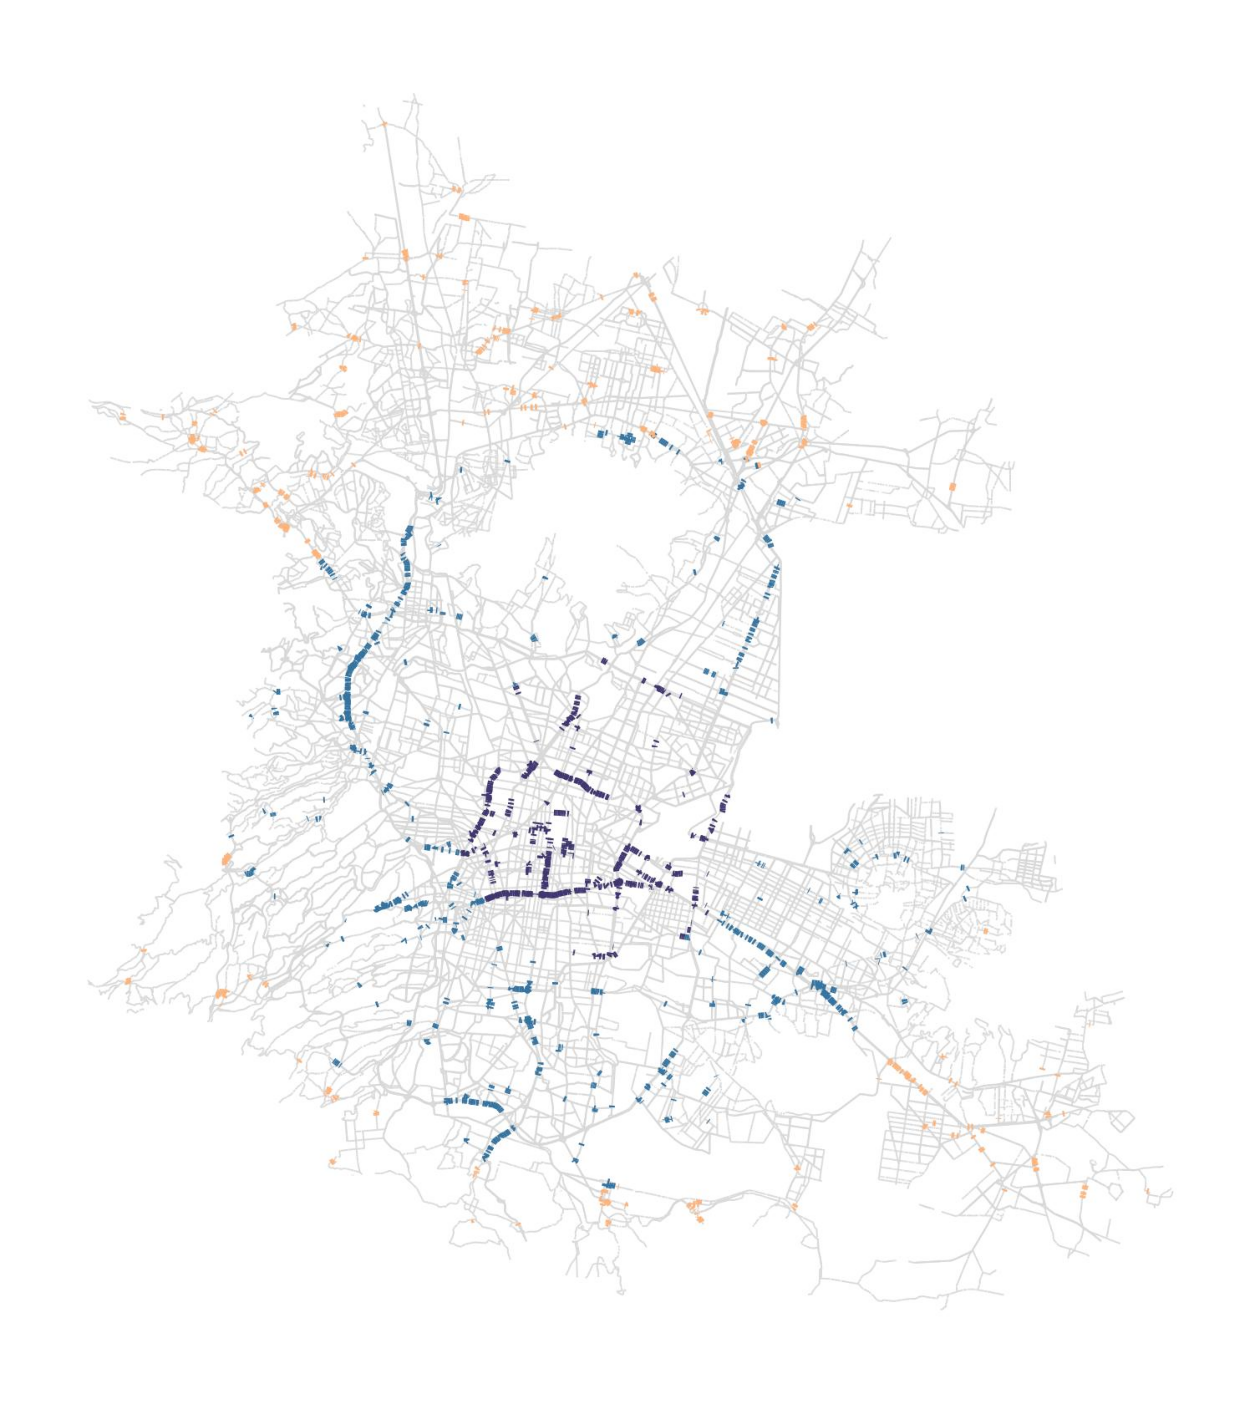

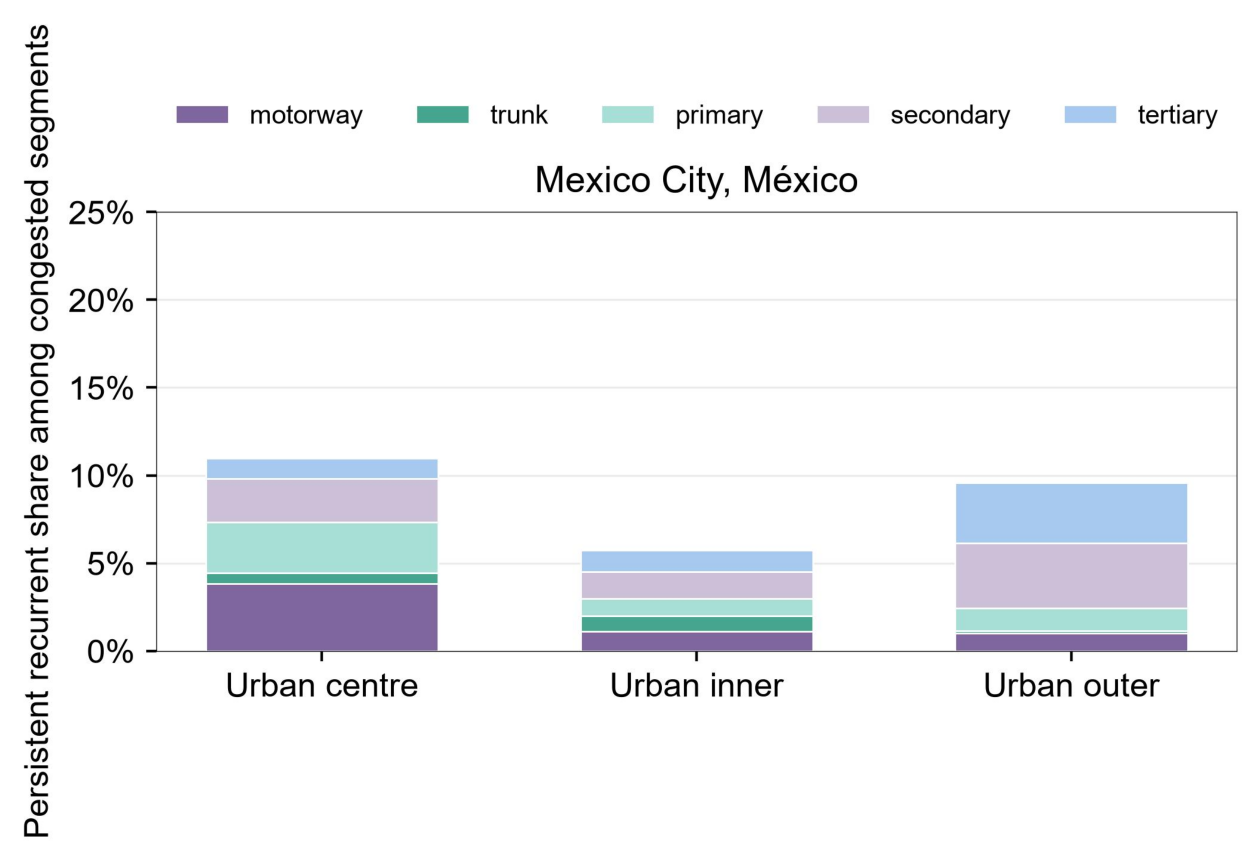

In [7]:
def city_maps(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 3: maps in panels d-i."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    STAGE0_DIR = Path(str(project_root / 'GIS/segment_congestion_all_cities/fig5_stage0_outputs'))

    FIG_OUT_DIR = output_dir
    FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CITY_MAP_DIR = FIG_OUT_DIR / "fig5c_city_maps"
    CITY_MAP_DIR.mkdir(parents=True, exist_ok=True)

    GROUP_SUMMARY_FP = STAGE0_DIR / "ring_group_summary.csv"
    MANIFEST_FP = STAGE0_DIR / "all_city_geojson_manifest.csv"

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]
    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }
    RING_COLORS = {
        "urban_centre": "#3f3770",
        "urban_inner": "#3573a1",
        "urban_outer": "#feb37b",
    }

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG  = 400

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10
    SPINE_LW = 0.25

    LINE_WIDTH = 1.6
    MARKER_SIZE = 6.5

    MAP_BASE_LINEWIDTH = 0.35
    MAP_PR_LINEWIDTH = 1.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    manifest_df = pd.read_csv(MANIFEST_FP)
    selected_cities = {'mexico-city, mexico'}
    manifest_df = manifest_df[manifest_df["city"].str.lower().isin(selected_cities)]
    if len(manifest_df) != 1:
        raise ValueError("Expected one matching city in the map manifest.")
    saved_count = 0
    skipped_count = 0

    for _, row in manifest_df.iterrows():
        city_label = row["city"]

        geo_val = row.get("processed_full_geojson", "")
        geo_fp_str = "" if pd.isna(geo_val) else str(geo_val).strip()

        if geo_fp_str == "":
            print(f"Skip {city_label}: no processed_full_geojson path")
            skipped_count += 1
            continue

        geo_fp = STAGE0_DIR / "processed_geojson_all_cities" / Path(geo_fp_str.replace("\\", "/")).name

        if not geo_fp.exists():
            print(f"Missing processed geojson: {geo_fp}")
            skipped_count += 1
            continue

        try:
            gdf = gpd.read_file(geo_fp)
        except Exception as e:
            print(f"Failed reading {geo_fp}: {e}")
            skipped_count += 1
            continue

        required_cols = {"segment_type", "ring_final"}
        missing_cols = required_cols - set(gdf.columns)
        if missing_cols:
            print(f"Skip {city_label}: missing columns {missing_cols}")
            skipped_count += 1
            continue

        safe_name = (
            str(city_label).lower()
            .replace(",", "")
            .replace(" ", "_")
            .replace("/", "_")
        )

        fig, ax = plt.subplots(figsize=(6.1, 5.2), dpi=DPI_SHOW)

        gdf.plot(ax=ax, color="#d9d9d9", linewidth=MAP_BASE_LINEWIDTH)

        pr = gdf[gdf["segment_type"] == "Persistent recurrent"].copy()

        for ring in RING_ORDER:
            sub = pr[pr["ring_final"] == ring]
            if len(sub) == 0:
                continue
            sub.plot(
                ax=ax,
                color=RING_COLORS[ring],
                linewidth=MAP_PR_LINEWIDTH
            )

        ax.set_axis_off()

        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.svg",
            bbox_inches="tight"
        )
        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )

        plt.close(fig)
        saved_count += 1

    print("\nFig.5c done.")
    print(f"Saved Fig.5c line plot to: {FIG_OUT_DIR}")
    print(f"Saved all city maps to: {CITY_MAP_DIR}")
    print(f"Saved city maps: {saved_count}")
    print(f"Skipped city maps: {skipped_count}")

def city_bars(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 6: bars in panels d-i; reads the saved matching results."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import re

    import unicodedata

    import numpy as np

    import pandas as pd

    import geopandas as gpd

    import matplotlib.pyplot as plt

    import matplotlib.ticker as mtick

    FIG_W = 5.5

    FIG_H = 3

    DPI = 600

    DPI_JPG = 400

    FONT_FAMILY = "Arial"

    TITLE_SIZE = 11

    LABEL_SIZE = 10

    TICK_SIZE = 10

    LEGEND_SIZE = 8

    SPINE_LW = 0.25

    BAR_WIDTH = 0.62

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]

    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }

    ROAD_ORDER = ["motorway", "trunk", "primary", "secondary", "tertiary"]

    ROAD_COLORS = {
        "motorway":  "#80669f",
        "trunk":     "#46a58f",
        "primary":   "#a7dfd6",
        "secondary": "#ccc0d9",
        "tertiary":  "#a7c9ef",
    }

    TARGET_HIGHWAYS = set(ROAD_ORDER)

    MAX_MATCH_DIST_M = 35.0

    DENOMINATOR_TARGET_FIVE_ONLY = True

    USE_LENGTH_IF_AVAILABLE = True

    YMAX_FIXED = 0.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def normalize_text(text):
        if text is None:
            return ""
        text = str(text).strip().lower()
        text = unicodedata.normalize("NFKD", text)
        text = "".join(ch for ch in text if not unicodedata.combining(ch))
        text = text.replace("&", "and")
        text = text.replace("_", " ")
        text = text.replace("-", " ")
        text = re.sub(r"[^\w\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def safe_name(text):
        s = normalize_text(text)
        s = s.replace(" ", "_")
        s = re.sub(r"_+", "_", s)
        return s

    def plot_city_stacked_bar(city_label, plot_df, total_df):
        x = np.arange(len(RING_ORDER))
        fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

        bottoms = np.zeros(len(RING_ORDER), dtype=float)

        for road in ROAD_ORDER:
            sub = (
                plot_df[plot_df["road_class"] == road]
                .set_index("ring_final")
                .reindex(RING_ORDER)
                .reset_index()
            )

            y = sub["share_of_all_congested"].values.astype(float)
            y = np.nan_to_num(y, nan=0.0)

            ax.bar(
                x,
                y,
                width=BAR_WIDTH,
                bottom=bottoms,
                color=ROAD_COLORS[road],
                edgecolor="white",
                linewidth=0.5,
                label=road
            )
            bottoms += y

        ax.set_ylim(0, YMAX_FIXED)
        ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

        ax.set_xticks(x)
        ax.set_xticklabels([RING_LABELS[r] for r in RING_ORDER])

        ax.set_ylabel("Persistent recurrent share among congested segments")
        ax.set_title(city_label)

        ax.grid(axis="y", alpha=0.25, linewidth=0.6)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_LW)

        ax.tick_params(axis="both", length=3, width=0.8)

        ax.legend(
            frameon=False,
            ncol=5,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.30)
        )

        fig.tight_layout()

        safe_city = safe_name(city_label)
        fig.savefig(FIG_DIR / f"{safe_city}_ring_highway_stacked.svg", bbox_inches="tight")
        fig.savefig(
            FIG_DIR / f"{safe_city}_ring_highway_stacked.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )
        plt.close(fig)
    FIG_DIR = output_dir
    stack_file = project_root / "GIS/segment_congestion_all_cities/fig5_highway_ring_outputs/csv/all_cities_ring_highway_stack_values.csv"
    stack = pd.read_csv(stack_file)
    stack = stack.loc[stack["city"] == 'Mexico City, México'].copy()
    if stack.empty:
        raise ValueError("City is missing from the saved bar table.")
    for city, city_data in stack.groupby("city", sort=False):
        total = city_data.groupby("ring_final", as_index=False)["share_of_all_congested"].sum().rename(columns={"share_of_all_congested": "total_pr_share"})
        plot_city_stacked_bar(city, city_data, total)

output_dir = OUTPUT_ROOT / "f"
with plt.rc_context():
    city_maps(DATA_DIR, PROJECT_ROOT, output_dir / "map")
with plt.rc_context():
    city_bars(DATA_DIR, PROJECT_ROOT, output_dir / "bars")
plt.close("all")
show_saved(output_dir / 'map/fig5c_city_maps/mexico-city_mexico.jpg')
show_saved(output_dir / 'bars/mexico_city_mexico_ring_highway_stacked.jpg')


## g — Sao Paulo
Source: `Fig5.ipynb`, cells 3 and 6. The map and corresponding stacked bars are kept together.

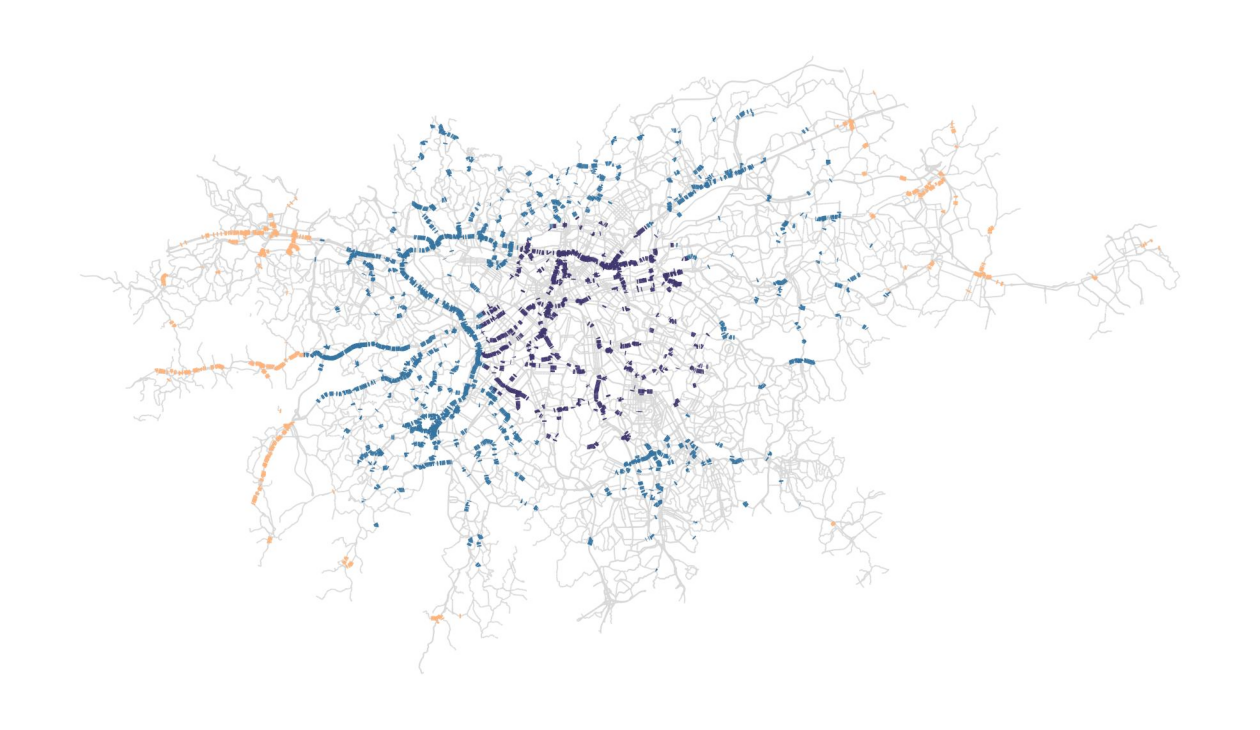

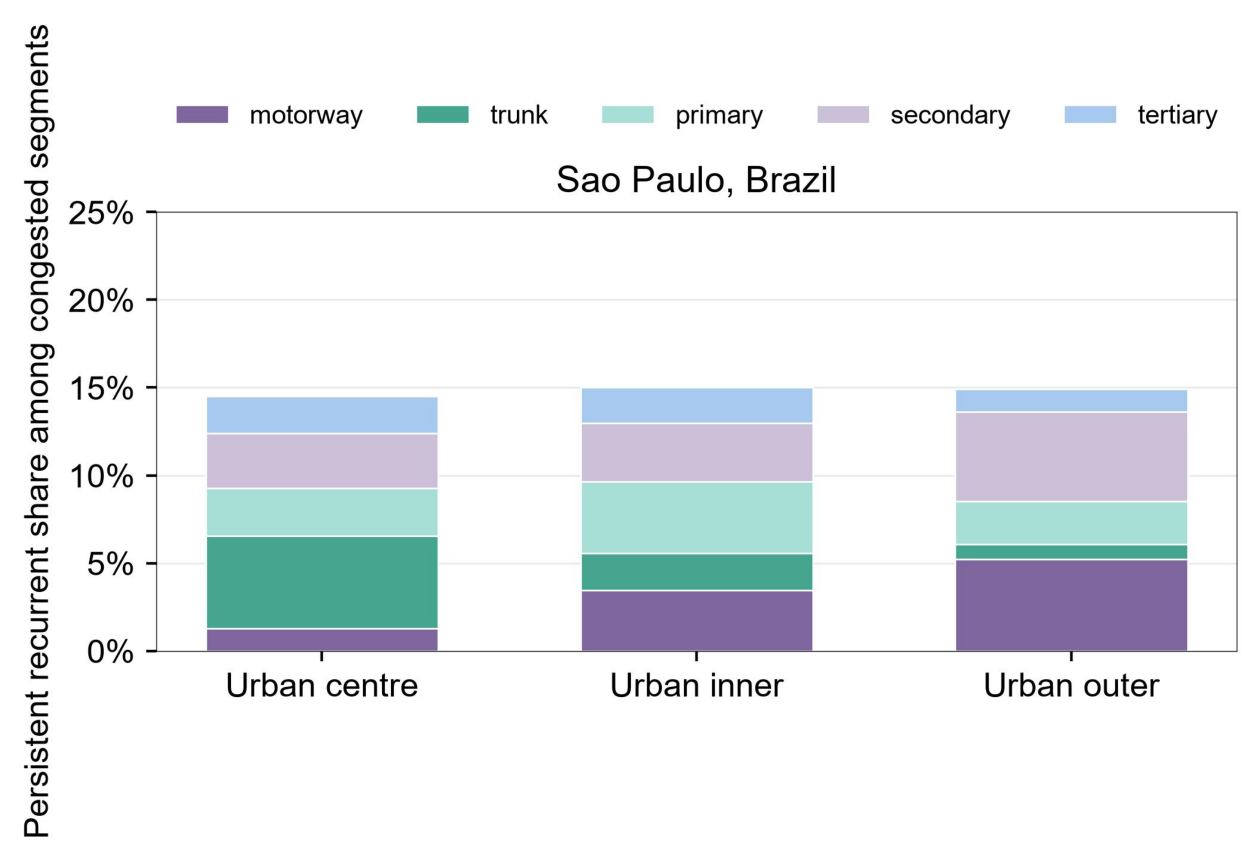

In [8]:
def city_maps(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 3: maps in panels d-i."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    STAGE0_DIR = Path(str(project_root / 'GIS/segment_congestion_all_cities/fig5_stage0_outputs'))

    FIG_OUT_DIR = output_dir
    FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CITY_MAP_DIR = FIG_OUT_DIR / "fig5c_city_maps"
    CITY_MAP_DIR.mkdir(parents=True, exist_ok=True)

    GROUP_SUMMARY_FP = STAGE0_DIR / "ring_group_summary.csv"
    MANIFEST_FP = STAGE0_DIR / "all_city_geojson_manifest.csv"

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]
    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }
    RING_COLORS = {
        "urban_centre": "#3f3770",
        "urban_inner": "#3573a1",
        "urban_outer": "#feb37b",
    }

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG  = 400

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10
    SPINE_LW = 0.25

    LINE_WIDTH = 1.6
    MARKER_SIZE = 6.5

    MAP_BASE_LINEWIDTH = 0.35
    MAP_PR_LINEWIDTH = 1.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    manifest_df = pd.read_csv(MANIFEST_FP)
    selected_cities = {'sao-paulo, brazil'}
    manifest_df = manifest_df[manifest_df["city"].str.lower().isin(selected_cities)]
    if len(manifest_df) != 1:
        raise ValueError("Expected one matching city in the map manifest.")
    saved_count = 0
    skipped_count = 0

    for _, row in manifest_df.iterrows():
        city_label = row["city"]

        geo_val = row.get("processed_full_geojson", "")
        geo_fp_str = "" if pd.isna(geo_val) else str(geo_val).strip()

        if geo_fp_str == "":
            print(f"Skip {city_label}: no processed_full_geojson path")
            skipped_count += 1
            continue

        geo_fp = STAGE0_DIR / "processed_geojson_all_cities" / Path(geo_fp_str.replace("\\", "/")).name

        if not geo_fp.exists():
            print(f"Missing processed geojson: {geo_fp}")
            skipped_count += 1
            continue

        try:
            gdf = gpd.read_file(geo_fp)
        except Exception as e:
            print(f"Failed reading {geo_fp}: {e}")
            skipped_count += 1
            continue

        required_cols = {"segment_type", "ring_final"}
        missing_cols = required_cols - set(gdf.columns)
        if missing_cols:
            print(f"Skip {city_label}: missing columns {missing_cols}")
            skipped_count += 1
            continue

        safe_name = (
            str(city_label).lower()
            .replace(",", "")
            .replace(" ", "_")
            .replace("/", "_")
        )

        fig, ax = plt.subplots(figsize=(6.1, 5.2), dpi=DPI_SHOW)

        gdf.plot(ax=ax, color="#d9d9d9", linewidth=MAP_BASE_LINEWIDTH)

        pr = gdf[gdf["segment_type"] == "Persistent recurrent"].copy()

        for ring in RING_ORDER:
            sub = pr[pr["ring_final"] == ring]
            if len(sub) == 0:
                continue
            sub.plot(
                ax=ax,
                color=RING_COLORS[ring],
                linewidth=MAP_PR_LINEWIDTH
            )

        ax.set_axis_off()

        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.svg",
            bbox_inches="tight"
        )
        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )

        plt.close(fig)
        saved_count += 1

    print("\nFig.5c done.")
    print(f"Saved Fig.5c line plot to: {FIG_OUT_DIR}")
    print(f"Saved all city maps to: {CITY_MAP_DIR}")
    print(f"Saved city maps: {saved_count}")
    print(f"Skipped city maps: {skipped_count}")

def city_bars(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 6: bars in panels d-i; reads the saved matching results."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import re

    import unicodedata

    import numpy as np

    import pandas as pd

    import geopandas as gpd

    import matplotlib.pyplot as plt

    import matplotlib.ticker as mtick

    FIG_W = 5.5

    FIG_H = 3

    DPI = 600

    DPI_JPG = 400

    FONT_FAMILY = "Arial"

    TITLE_SIZE = 11

    LABEL_SIZE = 10

    TICK_SIZE = 10

    LEGEND_SIZE = 8

    SPINE_LW = 0.25

    BAR_WIDTH = 0.62

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]

    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }

    ROAD_ORDER = ["motorway", "trunk", "primary", "secondary", "tertiary"]

    ROAD_COLORS = {
        "motorway":  "#80669f",
        "trunk":     "#46a58f",
        "primary":   "#a7dfd6",
        "secondary": "#ccc0d9",
        "tertiary":  "#a7c9ef",
    }

    TARGET_HIGHWAYS = set(ROAD_ORDER)

    MAX_MATCH_DIST_M = 35.0

    DENOMINATOR_TARGET_FIVE_ONLY = True

    USE_LENGTH_IF_AVAILABLE = True

    YMAX_FIXED = 0.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def normalize_text(text):
        if text is None:
            return ""
        text = str(text).strip().lower()
        text = unicodedata.normalize("NFKD", text)
        text = "".join(ch for ch in text if not unicodedata.combining(ch))
        text = text.replace("&", "and")
        text = text.replace("_", " ")
        text = text.replace("-", " ")
        text = re.sub(r"[^\w\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def safe_name(text):
        s = normalize_text(text)
        s = s.replace(" ", "_")
        s = re.sub(r"_+", "_", s)
        return s

    def plot_city_stacked_bar(city_label, plot_df, total_df):
        x = np.arange(len(RING_ORDER))
        fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

        bottoms = np.zeros(len(RING_ORDER), dtype=float)

        for road in ROAD_ORDER:
            sub = (
                plot_df[plot_df["road_class"] == road]
                .set_index("ring_final")
                .reindex(RING_ORDER)
                .reset_index()
            )

            y = sub["share_of_all_congested"].values.astype(float)
            y = np.nan_to_num(y, nan=0.0)

            ax.bar(
                x,
                y,
                width=BAR_WIDTH,
                bottom=bottoms,
                color=ROAD_COLORS[road],
                edgecolor="white",
                linewidth=0.5,
                label=road
            )
            bottoms += y

        ax.set_ylim(0, YMAX_FIXED)
        ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

        ax.set_xticks(x)
        ax.set_xticklabels([RING_LABELS[r] for r in RING_ORDER])

        ax.set_ylabel("Persistent recurrent share among congested segments")
        ax.set_title(city_label)

        ax.grid(axis="y", alpha=0.25, linewidth=0.6)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_LW)

        ax.tick_params(axis="both", length=3, width=0.8)

        ax.legend(
            frameon=False,
            ncol=5,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.30)
        )

        fig.tight_layout()

        safe_city = safe_name(city_label)
        fig.savefig(FIG_DIR / f"{safe_city}_ring_highway_stacked.svg", bbox_inches="tight")
        fig.savefig(
            FIG_DIR / f"{safe_city}_ring_highway_stacked.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )
        plt.close(fig)
    FIG_DIR = output_dir
    stack_file = project_root / "GIS/segment_congestion_all_cities/fig5_highway_ring_outputs/csv/all_cities_ring_highway_stack_values.csv"
    stack = pd.read_csv(stack_file)
    stack = stack.loc[stack["city"] == 'Sao Paulo, Brazil'].copy()
    if stack.empty:
        raise ValueError("City is missing from the saved bar table.")
    for city, city_data in stack.groupby("city", sort=False):
        total = city_data.groupby("ring_final", as_index=False)["share_of_all_congested"].sum().rename(columns={"share_of_all_congested": "total_pr_share"})
        plot_city_stacked_bar(city, city_data, total)

output_dir = OUTPUT_ROOT / "g"
with plt.rc_context():
    city_maps(DATA_DIR, PROJECT_ROOT, output_dir / "map")
with plt.rc_context():
    city_bars(DATA_DIR, PROJECT_ROOT, output_dir / "bars")
plt.close("all")
show_saved(output_dir / 'map/fig5c_city_maps/sao-paulo_brazil.jpg')
show_saved(output_dir / 'bars/sao_paulo_brazil_ring_highway_stacked.jpg')


## h — New York
Source: `Fig5.ipynb`, cells 3 and 6. The map and corresponding stacked bars are kept together.

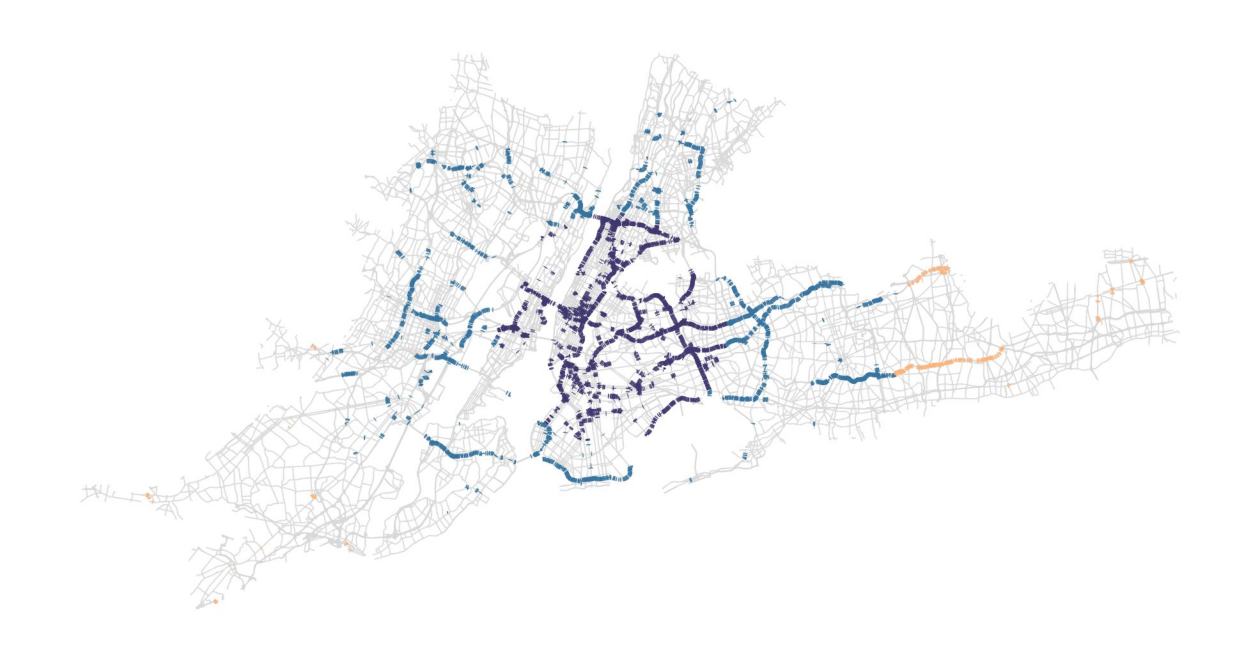

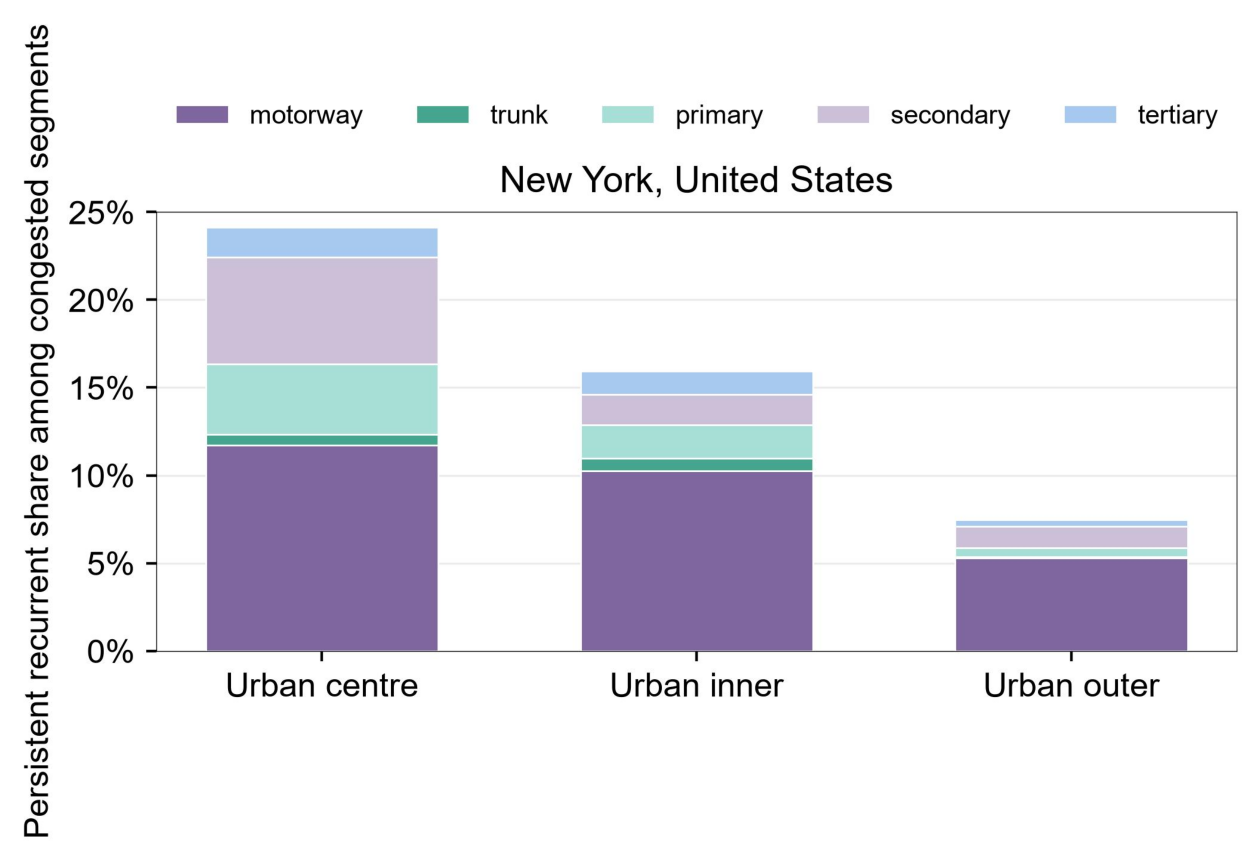

In [9]:
def city_maps(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 3: maps in panels d-i."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    STAGE0_DIR = Path(str(project_root / 'GIS/segment_congestion_all_cities/fig5_stage0_outputs'))

    FIG_OUT_DIR = output_dir
    FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CITY_MAP_DIR = FIG_OUT_DIR / "fig5c_city_maps"
    CITY_MAP_DIR.mkdir(parents=True, exist_ok=True)

    GROUP_SUMMARY_FP = STAGE0_DIR / "ring_group_summary.csv"
    MANIFEST_FP = STAGE0_DIR / "all_city_geojson_manifest.csv"

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]
    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }
    RING_COLORS = {
        "urban_centre": "#3f3770",
        "urban_inner": "#3573a1",
        "urban_outer": "#feb37b",
    }

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG  = 400

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10
    SPINE_LW = 0.25

    LINE_WIDTH = 1.6
    MARKER_SIZE = 6.5

    MAP_BASE_LINEWIDTH = 0.35
    MAP_PR_LINEWIDTH = 1.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    manifest_df = pd.read_csv(MANIFEST_FP)
    selected_cities = {'new york, united states'}
    manifest_df = manifest_df[manifest_df["city"].str.lower().isin(selected_cities)]
    if len(manifest_df) != 1:
        raise ValueError("Expected one matching city in the map manifest.")
    saved_count = 0
    skipped_count = 0

    for _, row in manifest_df.iterrows():
        city_label = row["city"]

        geo_val = row.get("processed_full_geojson", "")
        geo_fp_str = "" if pd.isna(geo_val) else str(geo_val).strip()

        if geo_fp_str == "":
            print(f"Skip {city_label}: no processed_full_geojson path")
            skipped_count += 1
            continue

        geo_fp = STAGE0_DIR / "processed_geojson_all_cities" / Path(geo_fp_str.replace("\\", "/")).name

        if not geo_fp.exists():
            print(f"Missing processed geojson: {geo_fp}")
            skipped_count += 1
            continue

        try:
            gdf = gpd.read_file(geo_fp)
        except Exception as e:
            print(f"Failed reading {geo_fp}: {e}")
            skipped_count += 1
            continue

        required_cols = {"segment_type", "ring_final"}
        missing_cols = required_cols - set(gdf.columns)
        if missing_cols:
            print(f"Skip {city_label}: missing columns {missing_cols}")
            skipped_count += 1
            continue

        safe_name = (
            str(city_label).lower()
            .replace(",", "")
            .replace(" ", "_")
            .replace("/", "_")
        )

        fig, ax = plt.subplots(figsize=(6.1, 5.2), dpi=DPI_SHOW)

        gdf.plot(ax=ax, color="#d9d9d9", linewidth=MAP_BASE_LINEWIDTH)

        pr = gdf[gdf["segment_type"] == "Persistent recurrent"].copy()

        for ring in RING_ORDER:
            sub = pr[pr["ring_final"] == ring]
            if len(sub) == 0:
                continue
            sub.plot(
                ax=ax,
                color=RING_COLORS[ring],
                linewidth=MAP_PR_LINEWIDTH
            )

        ax.set_axis_off()

        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.svg",
            bbox_inches="tight"
        )
        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )

        plt.close(fig)
        saved_count += 1

    print("\nFig.5c done.")
    print(f"Saved Fig.5c line plot to: {FIG_OUT_DIR}")
    print(f"Saved all city maps to: {CITY_MAP_DIR}")
    print(f"Saved city maps: {saved_count}")
    print(f"Skipped city maps: {skipped_count}")

def city_bars(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 6: bars in panels d-i; reads the saved matching results."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import re

    import unicodedata

    import numpy as np

    import pandas as pd

    import geopandas as gpd

    import matplotlib.pyplot as plt

    import matplotlib.ticker as mtick

    FIG_W = 5.5

    FIG_H = 3

    DPI = 600

    DPI_JPG = 400

    FONT_FAMILY = "Arial"

    TITLE_SIZE = 11

    LABEL_SIZE = 10

    TICK_SIZE = 10

    LEGEND_SIZE = 8

    SPINE_LW = 0.25

    BAR_WIDTH = 0.62

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]

    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }

    ROAD_ORDER = ["motorway", "trunk", "primary", "secondary", "tertiary"]

    ROAD_COLORS = {
        "motorway":  "#80669f",
        "trunk":     "#46a58f",
        "primary":   "#a7dfd6",
        "secondary": "#ccc0d9",
        "tertiary":  "#a7c9ef",
    }

    TARGET_HIGHWAYS = set(ROAD_ORDER)

    MAX_MATCH_DIST_M = 35.0

    DENOMINATOR_TARGET_FIVE_ONLY = True

    USE_LENGTH_IF_AVAILABLE = True

    YMAX_FIXED = 0.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def normalize_text(text):
        if text is None:
            return ""
        text = str(text).strip().lower()
        text = unicodedata.normalize("NFKD", text)
        text = "".join(ch for ch in text if not unicodedata.combining(ch))
        text = text.replace("&", "and")
        text = text.replace("_", " ")
        text = text.replace("-", " ")
        text = re.sub(r"[^\w\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def safe_name(text):
        s = normalize_text(text)
        s = s.replace(" ", "_")
        s = re.sub(r"_+", "_", s)
        return s

    def plot_city_stacked_bar(city_label, plot_df, total_df):
        x = np.arange(len(RING_ORDER))
        fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

        bottoms = np.zeros(len(RING_ORDER), dtype=float)

        for road in ROAD_ORDER:
            sub = (
                plot_df[plot_df["road_class"] == road]
                .set_index("ring_final")
                .reindex(RING_ORDER)
                .reset_index()
            )

            y = sub["share_of_all_congested"].values.astype(float)
            y = np.nan_to_num(y, nan=0.0)

            ax.bar(
                x,
                y,
                width=BAR_WIDTH,
                bottom=bottoms,
                color=ROAD_COLORS[road],
                edgecolor="white",
                linewidth=0.5,
                label=road
            )
            bottoms += y

        ax.set_ylim(0, YMAX_FIXED)
        ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

        ax.set_xticks(x)
        ax.set_xticklabels([RING_LABELS[r] for r in RING_ORDER])

        ax.set_ylabel("Persistent recurrent share among congested segments")
        ax.set_title(city_label)

        ax.grid(axis="y", alpha=0.25, linewidth=0.6)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_LW)

        ax.tick_params(axis="both", length=3, width=0.8)

        ax.legend(
            frameon=False,
            ncol=5,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.30)
        )

        fig.tight_layout()

        safe_city = safe_name(city_label)
        fig.savefig(FIG_DIR / f"{safe_city}_ring_highway_stacked.svg", bbox_inches="tight")
        fig.savefig(
            FIG_DIR / f"{safe_city}_ring_highway_stacked.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )
        plt.close(fig)
    FIG_DIR = output_dir
    stack_file = project_root / "GIS/segment_congestion_all_cities/fig5_highway_ring_outputs/csv/all_cities_ring_highway_stack_values.csv"
    stack = pd.read_csv(stack_file)
    stack = stack.loc[stack["city"] == 'New York, United States'].copy()
    if stack.empty:
        raise ValueError("City is missing from the saved bar table.")
    for city, city_data in stack.groupby("city", sort=False):
        total = city_data.groupby("ring_final", as_index=False)["share_of_all_congested"].sum().rename(columns={"share_of_all_congested": "total_pr_share"})
        plot_city_stacked_bar(city, city_data, total)

output_dir = OUTPUT_ROOT / "h"
with plt.rc_context():
    city_maps(DATA_DIR, PROJECT_ROOT, output_dir / "map")
with plt.rc_context():
    city_bars(DATA_DIR, PROJECT_ROOT, output_dir / "bars")
plt.close("all")
show_saved(output_dir / 'map/fig5c_city_maps/new_york_united_states.jpg')
show_saved(output_dir / 'bars/new_york_united_states_ring_highway_stacked.jpg')


## i — Bangkok
Source: `Fig5.ipynb`, cells 3 and 6. The map and corresponding stacked bars are kept together.

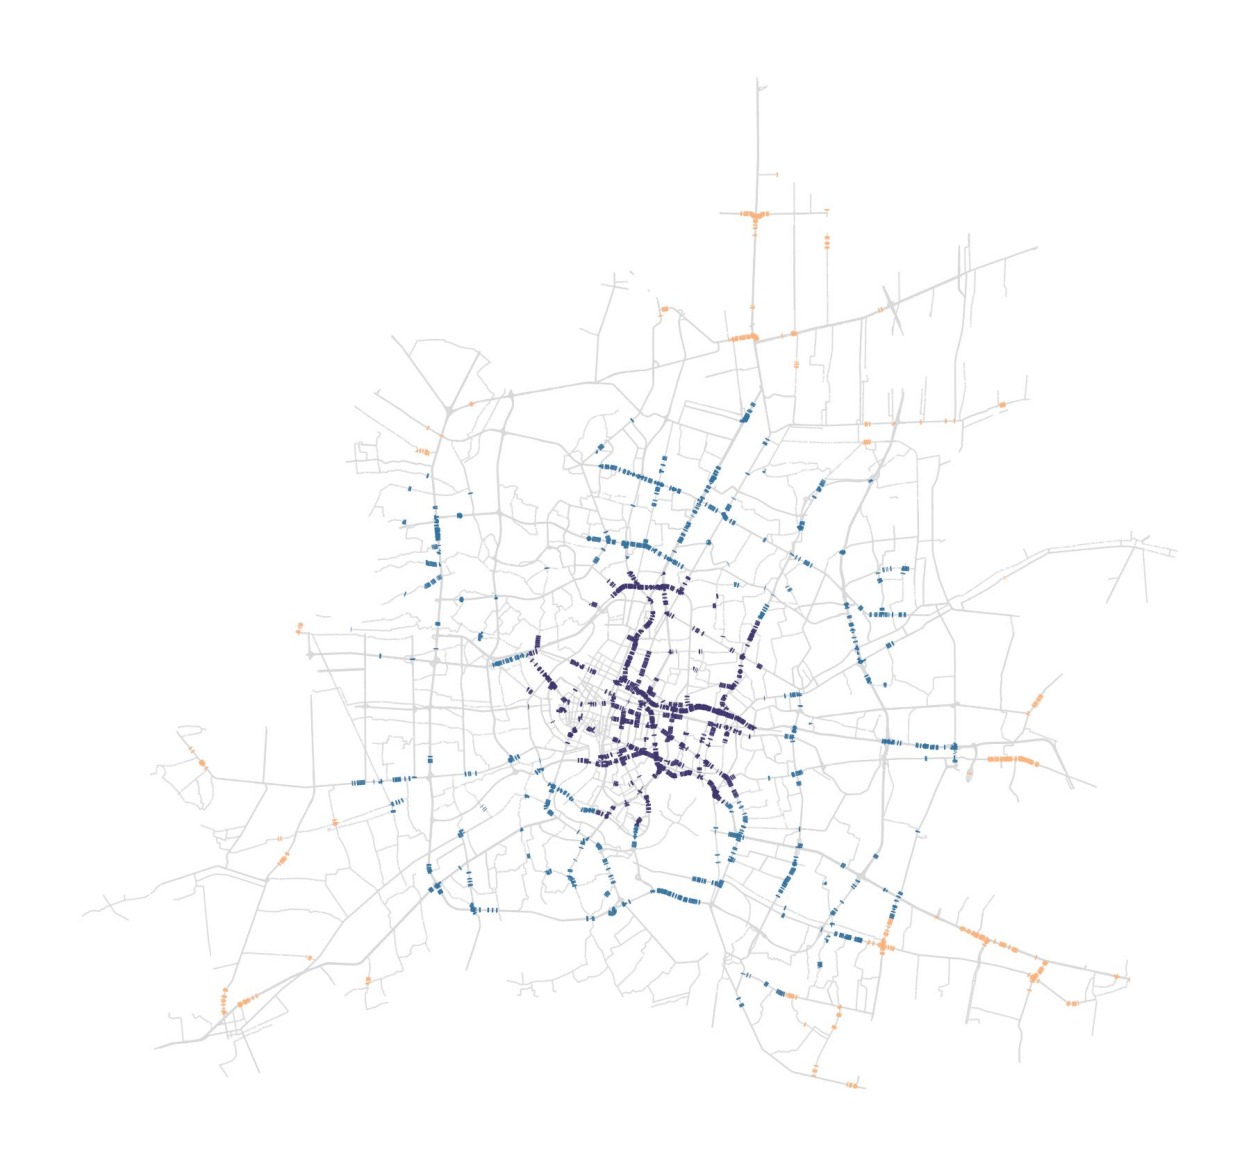

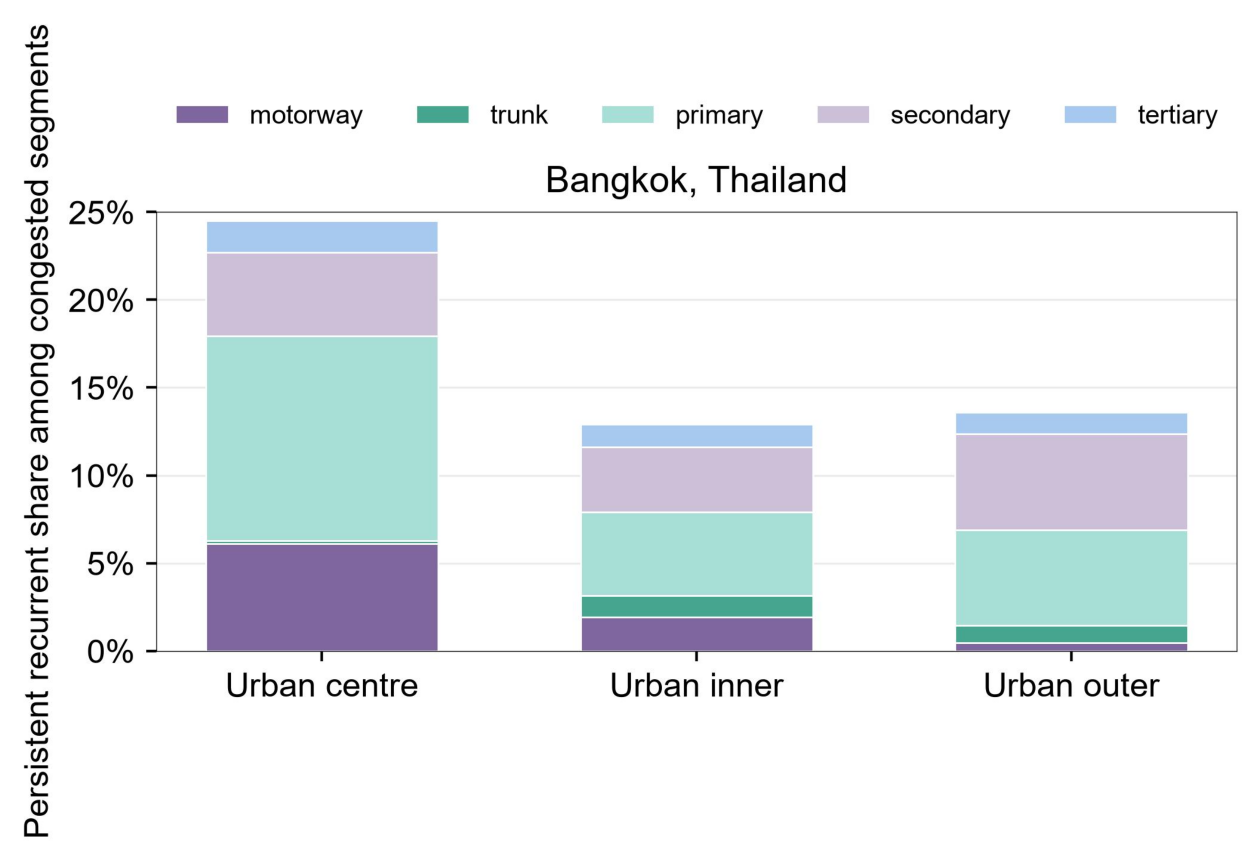

In [10]:
def city_maps(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 3: maps in panels d-i."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick

    STAGE0_DIR = Path(str(project_root / 'GIS/segment_congestion_all_cities/fig5_stage0_outputs'))

    FIG_OUT_DIR = output_dir
    FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CODE_OUT_DIR = output_dir
    CODE_OUT_DIR.mkdir(parents=True, exist_ok=True)

    CITY_MAP_DIR = FIG_OUT_DIR / "fig5c_city_maps"
    CITY_MAP_DIR.mkdir(parents=True, exist_ok=True)

    GROUP_SUMMARY_FP = STAGE0_DIR / "ring_group_summary.csv"
    MANIFEST_FP = STAGE0_DIR / "all_city_geojson_manifest.csv"

    GROUP_ORDER = ["Small (<1M)", "Medium (1-5M)", "Large (5-10M)", "Mega (10M+)"]
    GROUP_COLORS = {
        "Small (<1M)":   "#808080",
        "Medium (1-5M)": "#3573a1",
        "Large (5-10M)": "#d76552",
        "Mega (10M+)":   "#3f3770",
    }

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]
    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }
    RING_COLORS = {
        "urban_centre": "#3f3770",
        "urban_inner": "#3573a1",
        "urban_outer": "#feb37b",
    }

    DPI_SHOW = 140
    DPI_SAVE = 600
    DPI_JPG  = 400

    FONT_FAMILY = "Arial"
    TITLE_SIZE = 12
    LABEL_SIZE = 12
    TICK_SIZE = 12
    LEGEND_SIZE = 10
    SPINE_LW = 0.25

    LINE_WIDTH = 1.6
    MARKER_SIZE = 6.5

    MAP_BASE_LINEWIDTH = 0.35
    MAP_PR_LINEWIDTH = 1.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    manifest_df = pd.read_csv(MANIFEST_FP)
    selected_cities = {'bangkok, thailand'}
    manifest_df = manifest_df[manifest_df["city"].str.lower().isin(selected_cities)]
    if len(manifest_df) != 1:
        raise ValueError("Expected one matching city in the map manifest.")
    saved_count = 0
    skipped_count = 0

    for _, row in manifest_df.iterrows():
        city_label = row["city"]

        geo_val = row.get("processed_full_geojson", "")
        geo_fp_str = "" if pd.isna(geo_val) else str(geo_val).strip()

        if geo_fp_str == "":
            print(f"Skip {city_label}: no processed_full_geojson path")
            skipped_count += 1
            continue

        geo_fp = STAGE0_DIR / "processed_geojson_all_cities" / Path(geo_fp_str.replace("\\", "/")).name

        if not geo_fp.exists():
            print(f"Missing processed geojson: {geo_fp}")
            skipped_count += 1
            continue

        try:
            gdf = gpd.read_file(geo_fp)
        except Exception as e:
            print(f"Failed reading {geo_fp}: {e}")
            skipped_count += 1
            continue

        required_cols = {"segment_type", "ring_final"}
        missing_cols = required_cols - set(gdf.columns)
        if missing_cols:
            print(f"Skip {city_label}: missing columns {missing_cols}")
            skipped_count += 1
            continue

        safe_name = (
            str(city_label).lower()
            .replace(",", "")
            .replace(" ", "_")
            .replace("/", "_")
        )

        fig, ax = plt.subplots(figsize=(6.1, 5.2), dpi=DPI_SHOW)

        gdf.plot(ax=ax, color="#d9d9d9", linewidth=MAP_BASE_LINEWIDTH)

        pr = gdf[gdf["segment_type"] == "Persistent recurrent"].copy()

        for ring in RING_ORDER:
            sub = pr[pr["ring_final"] == ring]
            if len(sub) == 0:
                continue
            sub.plot(
                ax=ax,
                color=RING_COLORS[ring],
                linewidth=MAP_PR_LINEWIDTH
            )

        ax.set_axis_off()

        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.svg",
            bbox_inches="tight"
        )
        fig.savefig(
            CITY_MAP_DIR / f"{safe_name}.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )

        plt.close(fig)
        saved_count += 1

    print("\nFig.5c done.")
    print(f"Saved Fig.5c line plot to: {FIG_OUT_DIR}")
    print(f"Saved all city maps to: {CITY_MAP_DIR}")
    print(f"Saved city maps: {saved_count}")
    print(f"Skipped city maps: {skipped_count}")

def city_bars(data_dir, project_root, output_dir):
    """Fig5.ipynb, cell 6: bars in panels d-i; reads the saved matching results."""
    output_dir.mkdir(parents=True, exist_ok=True)
    from pathlib import Path

    import re

    import unicodedata

    import numpy as np

    import pandas as pd

    import geopandas as gpd

    import matplotlib.pyplot as plt

    import matplotlib.ticker as mtick

    FIG_W = 5.5

    FIG_H = 3

    DPI = 600

    DPI_JPG = 400

    FONT_FAMILY = "Arial"

    TITLE_SIZE = 11

    LABEL_SIZE = 10

    TICK_SIZE = 10

    LEGEND_SIZE = 8

    SPINE_LW = 0.25

    BAR_WIDTH = 0.62

    RING_ORDER = ["urban_centre", "urban_inner", "urban_outer"]

    RING_LABELS = {
        "urban_centre": "Urban centre",
        "urban_inner": "Urban inner",
        "urban_outer": "Urban outer",
    }

    ROAD_ORDER = ["motorway", "trunk", "primary", "secondary", "tertiary"]

    ROAD_COLORS = {
        "motorway":  "#80669f",
        "trunk":     "#46a58f",
        "primary":   "#a7dfd6",
        "secondary": "#ccc0d9",
        "tertiary":  "#a7c9ef",
    }

    TARGET_HIGHWAYS = set(ROAD_ORDER)

    MAX_MATCH_DIST_M = 35.0

    DENOMINATOR_TARGET_FIVE_ONLY = True

    USE_LENGTH_IF_AVAILABLE = True

    YMAX_FIXED = 0.25

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": LABEL_SIZE,
        "axes.titlesize": TITLE_SIZE,
        "axes.labelsize": LABEL_SIZE,
        "xtick.labelsize": TICK_SIZE,
        "ytick.labelsize": TICK_SIZE,
        "legend.fontsize": LEGEND_SIZE,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    })

    def normalize_text(text):
        if text is None:
            return ""
        text = str(text).strip().lower()
        text = unicodedata.normalize("NFKD", text)
        text = "".join(ch for ch in text if not unicodedata.combining(ch))
        text = text.replace("&", "and")
        text = text.replace("_", " ")
        text = text.replace("-", " ")
        text = re.sub(r"[^\w\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def safe_name(text):
        s = normalize_text(text)
        s = s.replace(" ", "_")
        s = re.sub(r"_+", "_", s)
        return s

    def plot_city_stacked_bar(city_label, plot_df, total_df):
        x = np.arange(len(RING_ORDER))
        fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

        bottoms = np.zeros(len(RING_ORDER), dtype=float)

        for road in ROAD_ORDER:
            sub = (
                plot_df[plot_df["road_class"] == road]
                .set_index("ring_final")
                .reindex(RING_ORDER)
                .reset_index()
            )

            y = sub["share_of_all_congested"].values.astype(float)
            y = np.nan_to_num(y, nan=0.0)

            ax.bar(
                x,
                y,
                width=BAR_WIDTH,
                bottom=bottoms,
                color=ROAD_COLORS[road],
                edgecolor="white",
                linewidth=0.5,
                label=road
            )
            bottoms += y

        ax.set_ylim(0, YMAX_FIXED)
        ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

        ax.set_xticks(x)
        ax.set_xticklabels([RING_LABELS[r] for r in RING_ORDER])

        ax.set_ylabel("Persistent recurrent share among congested segments")
        ax.set_title(city_label)

        ax.grid(axis="y", alpha=0.25, linewidth=0.6)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(SPINE_LW)

        ax.tick_params(axis="both", length=3, width=0.8)

        ax.legend(
            frameon=False,
            ncol=5,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.30)
        )

        fig.tight_layout()

        safe_city = safe_name(city_label)
        fig.savefig(FIG_DIR / f"{safe_city}_ring_highway_stacked.svg", bbox_inches="tight")
        fig.savefig(
            FIG_DIR / f"{safe_city}_ring_highway_stacked.jpg",
            dpi=DPI_JPG,
            bbox_inches="tight",
            format="jpg"
        )
        plt.close(fig)
    FIG_DIR = output_dir
    stack_file = project_root / "GIS/segment_congestion_all_cities/fig5_highway_ring_outputs/csv/all_cities_ring_highway_stack_values.csv"
    stack = pd.read_csv(stack_file)
    stack = stack.loc[stack["city"] == 'Bangkok, Thailand'].copy()
    if stack.empty:
        raise ValueError("City is missing from the saved bar table.")
    for city, city_data in stack.groupby("city", sort=False):
        total = city_data.groupby("ring_final", as_index=False)["share_of_all_congested"].sum().rename(columns={"share_of_all_congested": "total_pr_share"})
        plot_city_stacked_bar(city, city_data, total)

output_dir = OUTPUT_ROOT / "i"
with plt.rc_context():
    city_maps(DATA_DIR, PROJECT_ROOT, output_dir / "map")
with plt.rc_context():
    city_bars(DATA_DIR, PROJECT_ROOT, output_dir / "bars")
plt.close("all")
show_saved(output_dir / 'map/fig5c_city_maps/bangkok_thailand.jpg')
show_saved(output_dir / 'bars/bangkok_thailand_ring_highway_stacked.jpg')
